In [ ]:
!pip install streamlit plotly

In [ ]:
import streamlit as st
import plotly.express as px
import pandas as pd
import numpy as np
from PIL import Image

print("All dashboard libraries imported successfully!")

All dashboard libraries imported successfully!


In [ ]:
import os

model_files = [
    "/content/densenet_ensemble_member.keras",
    "/content/efficientnet_ensemble_member.keras",
    "/content/best_class_weighted.keras",
    "/content/best_efficient.keras"
]

for path in model_files:
    if os.path.exists(path):
        print("FOUND:", path)
    else:
        print("NOT FOUND:", path)

FOUND: /content/densenet_ensemble_member.keras
FOUND: /content/efficientnet_ensemble_member.keras
FOUND: /content/best_class_weighted.keras
FOUND: /content/best_efficient.keras


In [ ]:
import os
import zipfile
import tensorflow as tf

model_paths = [
    "/content/densenet_ensemble_member.keras",
    "/content/efficientnet_ensemble_member.keras"
]

# Let's inspect the files to see if they are valid zip files
for path in model_paths:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"File: {path} | Size: {size_mb:.2f} MB")
        try:
            with zipfile.ZipFile(path, 'r') as zf:
                bad_file = zf.testzip()
                if bad_file is None:
                    print("  -> ZIP status: VALID")
                else:
                    print(f"  -> ZIP status: CORRUPT (First bad file: {bad_file})")
        except Exception as e:
            print(f"  -> ZIP status: FAILED TO OPEN ({type(e).__name__}: {e})")
    else:
        print(f"File: {path} | DOES NOT EXIST")

print("\nPlease re-upload or re-save your models if any of them are corrupt or 0 MB.")

File: /content/densenet_ensemble_member.keras | Size: 33.13 MB
  -> ZIP status: VALID
File: /content/efficientnet_ensemble_member.keras | Size: 47.01 MB
  -> ZIP status: VALID

Please re-upload or re-save your models if any of them are corrupt or 0 MB.


In [ ]:
import tensorflow as tf

try:
    test_model = tf.keras.models.load_model(
        "/content/densenet_ensemble_member.keras",
        compile=False
    )

    print("SUCCESS: DenseNet model loaded!")
    print("Model name:", test_model.name)
    print("Input shape:", test_model.input_shape)
    print("Output shape:", test_model.output_shape)

except Exception as e:
    print("ERROR: DenseNet could not be loaded.")
    print(type(e).__name__, str(e))

SUCCESS: DenseNet model loaded!
Model name: DenseNet121_MRI_Classifier
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)


In [ ]:
import tensorflow as tf

try:
    test_model = tf.keras.models.load_model(
        "/content/efficientnet_ensemble_member.keras",
        compile=False
    )

    print("SUCCESS: EfficientNet model loaded!")
    print("Model name:", test_model.name)
    print("Input shape:", test_model.input_shape)
    print("Output shape:", test_model.output_shape)

except Exception as e:
    print("ERROR:", type(e).__name__, str(e))

SUCCESS: EfficientNet model loaded!
Model name: sequential_1
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
from PIL import Image

# Page configuration
st.set_page_config(
    page_title="BrainScan AI",
    page_icon="🧠",
    layout="wide"
)

# Dashboard styling
st.markdown("""
<style>
.stApp {
    background-color: #0b1220;
    color: white;
}

h1, h2, h3 {
    color: #60a5fa;
}

[data-testid="stSidebar"] {
    background-color: #111c32;
}

.stButton button {
    background-color: #2563eb;
    color: white;
    border-radius: 8px;
}
</style>
""", unsafe_allow_html=True)

# Dashboard heading
st.title("🧠 BrainScan AI")
st.subheader("CNN-Based Brain MRI Classification System")

st.markdown("""
Welcome to BrainScan AI, an AI-assisted MRI classification
dashboard designed to analyse brain MRI images.
""")

# Sidebar navigation
st.sidebar.title("Navigation")

page = st.sidebar.radio(
    "Select a section",
    [
        "Dashboard",
        "MRI Image Analysis",
        "Analytics",
        "Model Information",
        "Analysis History"
    ]
)

if page == "Dashboard":

    st.header("Dashboard Overview")

    col1, col2, col3 = st.columns(3)

    col1.metric("Classification Classes", "3")
    col2.metric("Image Input Size", "224 × 224")
    col3.metric("Model Type", "CNN Ensemble")

    st.info(
        "Upload an MRI image using the MRI Image Analysis section "
        "to begin classification."
    )

elif page == "MRI Image Analysis":

    st.header("MRI Image Analysis")

    uploaded_files = st.file_uploader(
        "Upload brain MRI images",
        type=["jpg", "jpeg", "png"],
        accept_multiple_files=True
    )

    if uploaded_files:
        for uploaded_file in uploaded_files:
            image = Image.open(uploaded_file).convert("RGB")

            st.image(
                image,
                caption=uploaded_file.name,
                width=300
            )

        st.info(
            "Image upload is working. Model prediction integration "
            "will be added in the next implementation stage."
        )

elif page == "Analytics":

    st.header("Analytics")

    st.info(
        "Prediction analytics will appear here once the model "
        "prediction functionality has been connected."
    )

elif page == "Model Information":

    st.header("Model Information")

    st.write("Model architecture: CNN Ensemble")
    st.write("Framework: TensorFlow / Keras")
    st.write("Input dimensions: 224 × 224 × 3")
    st.write("Output classes: 3")

    st.write("Classification categories:")
    st.write("- Normal")
    st.write("- Brain Tumour")
    st.write("- Stroke")

elif page == "Analysis History":

    st.header("Analysis History")

    st.info(
        "Previous MRI classification results will be displayed here."
    )

st.divider()

st.caption(
    "BrainScan AI | Final-Year Research Project | "
    "Research prototype — not a clinically validated diagnostic system."
)

Writing app.py


In [ ]:
!pip install pyngrok

In [ ]:
!streamlit run app.py &>/content/streamlit.log &

In [ ]:
!cat /content/streamlit.log

In [ ]:
!pip install -q streamlit pyngrok

In [ ]:
import streamlit
import pyngrok

print("Streamlit version:", streamlit.__version__)
print("Streamlit installed successfully!")

Streamlit version: 1.67.0
Streamlit installed successfully!


In [ ]:
!python -m streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [ ]:
!cat /content/streamlit.log

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3LpH2nFlHgxKVhazDuQAN3jn5Ep_87eLRfpJ3mpr6hWibgRMk")

public_url = ngrok.connect(8501)

print("Your BrainScan AI Dashboard:")
print(public_url)

Your BrainScan AI Dashboard:
NgrokTunnel: "https://moistness-mahogany-swifter.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
import tensorflow as tf

# Load the models first so they are defined in memory
densenet_model = tf.keras.models.load_model("/content/densenet_ensemble_member.keras", compile=False)
efficientnet_model = tf.keras.models.load_model("/content/efficientnet_ensemble_member.keras", compile=False)

print("DENSENET MODEL LAYERS")
print("----------------------")
for layer in densenet_model.layers:
    print(layer.name, ":", layer.__class__.__name__)

print("\nEFFICIENTNET MODEL LAYERS")
print("-------------------------")
for layer in efficientnet_model.layers:
    print(layer.name, ":", layer.__class__.__name__)

DENSENET MODEL LAYERS
----------------------
input_layer_1 : InputLayer
densenet121 : Functional
global_average_pooling2d : GlobalAveragePooling2D
dropout : Dropout
classification_output : Dense

EFFICIENTNET MODEL LAYERS
-------------------------
efficientnetb0 : Functional
dropout : Dropout
dense : Dense


In [ ]:
print("DENSENET121 FEATURE EXTRACTOR")
for layer in densenet_model.layers[1].layers[:12]:
    print(layer.name, ":", layer.__class__.__name__)

print("\nEFFICIENTNETB0 FEATURE EXTRACTOR")
for layer in efficientnet_model.layers[0].layers[:12]:
    print(layer.name, ":", layer.__class__.__name__)

DENSENET121 FEATURE EXTRACTOR
input_layer : InputLayer
zero_padding2d : ZeroPadding2D
conv1_conv : Conv2D
conv1_bn : BatchNormalization
conv1_relu : Activation
zero_padding2d_1 : ZeroPadding2D
pool1 : MaxPooling2D
conv2_block1_0_bn : BatchNormalization
conv2_block1_0_relu : Activation
conv2_block1_1_conv : Conv2D
conv2_block1_1_bn : BatchNormalization
conv2_block1_1_relu : Activation

EFFICIENTNETB0 FEATURE EXTRACTOR
input_layer : InputLayer
rescaling : Rescaling
normalization : Normalization
rescaling_1 : Rescaling
stem_conv_pad : ZeroPadding2D
stem_conv : Conv2D
stem_bn : BatchNormalization
stem_activation : Activation
block1a_dwconv : DepthwiseConv2D
block1a_bn : BatchNormalization
block1a_activation : Activation
block1a_se_squeeze : GlobalAveragePooling2D


In [ ]:
print("DENSENET MODEL INPUT")
print(densenet_model.inputs)

print("\nEFFICIENTNET MODEL INPUT")
print(efficientnet_model.inputs)

print("\nEFFICIENTNET RESCALING CONFIGURATION")

for layer in efficientnet_model.layers[0].layers:
    if isinstance(layer, tf.keras.layers.Rescaling):
        print(layer.name, layer.get_config())

DENSENET MODEL INPUT
[<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer_1>]

EFFICIENTNET MODEL INPUT
[<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer_1>]

EFFICIENTNET RESCALING CONFIGURATION
rescaling {'name': 'rescaling', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'scale': 0.00392156862745098, 'offset': 0.0}
rescaling_1 {'name': 'rescaling_1', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'scale': [2.0896918976428642, 2.1128856368212916, 2.1081851067789197], 'offset': 0.0}


In [ ]:
import tensorflow as tf
import numpy as np
from PIL import Image

# Load the two ensemble-member models
densenet_model = tf.keras.models.load_model(
    "/content/densenet_ensemble_member.keras",
    compile=False
)

efficientnet_model = tf.keras.models.load_model(
    "/content/efficientnet_ensemble_member.keras",
    compile=False
)

print("Both models loaded successfully!")

Both models loaded successfully!


In [ ]:
from PIL import Image
import numpy as np

def preprocess_mri_image(uploaded_image):

    # Convert image to RGB
    image = uploaded_image.convert("RGB")

    # Resize image
    image = image.resize((224, 224))

    # Convert image to NumPy array
    image_array = np.array(image, dtype=np.float32)

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    return image_array

print("MRI image preprocessing function created successfully!")

MRI image preprocessing function created successfully!


In [ ]:
from google.colab import files
from PIL import Image
import io

# Upload an MRI image
uploaded_files = files.upload()

# Read the uploaded image
for filename in uploaded_files.keys():
    image = Image.open(io.BytesIO(uploaded_files[filename]))

    # Preprocess the image
    processed_image = preprocess_mri_image(image)

    print("Image name:", filename)
    print("Original image size:", image.size)
    print("Processed image shape:", processed_image.shape)

Saving WhatsApp Image 2026-11-08 at 15.24.59.png to WhatsApp Image 2026-11-08 at 15.24.59.png
Image name: WhatsApp Image 2026-11-08 at 15.24.59.png
Original image size: (1053, 1128)
Processed image shape: (1, 224, 224, 3)


In [ ]:
# Generate predictions using both models
densenet_prediction = densenet_model.predict(
    processed_image, verbose=0
)

efficientnet_prediction = efficientnet_model.predict(
    processed_image, verbose=0
)

print("DenseNet output:", densenet_prediction)
print("EfficientNet output:", efficientnet_prediction)

print("\nDenseNet output shape:", densenet_prediction.shape)
print("EfficientNet output shape:", efficientnet_prediction.shape)

DenseNet output: [[0.0147187  0.9788449  0.00643637]]
EfficientNet output: [[1.0311843e-02 5.2589818e-04 9.8916221e-01]]

DenseNet output shape: (1, 3)
EfficientNet output shape: (1, 3)


In [ ]:
# Generate predictions from both models
densenet_prediction = densenet_model.predict(
    processed_image, verbose=0
)

efficientnet_prediction = efficientnet_model.predict(
    processed_image, verbose=0
)

# Combine predictions using soft voting
ensemble_prediction = (
    densenet_prediction + efficientnet_prediction
) / 2

# Find the class index with the highest average probability
predicted_class_index = np.argmax(ensemble_prediction[0])

# Get the prediction confidence
confidence = ensemble_prediction[0][predicted_class_index] * 100

# Display results
print("FINAL ENSEMBLE PREDICTION")
print("-------------------------")

for i, probability in enumerate(ensemble_prediction[0]):
    print(f"Class index {i}: {probability * 100:.2f}%")

print("\nPredicted class index:", predicted_class_index)
print(f"Prediction confidence: {confidence:.2f}%")

FINAL ENSEMBLE PREDICTION
-------------------------
Class index 0: 1.25%
Class index 1: 48.97%
Class index 2: 49.78%

Predicted class index: 2
Prediction confidence: 49.78%


In [ ]:
CLASS_NAMES = ["Tumour", "Stroke", "Normal"]

def predict_ensemble(image):

    # Prepare the MRI image
    processed_image = preprocess_mri_image(image)

    # Get predictions from both models
    densenet_prediction = densenet_model.predict(
        processed_image, verbose=0
    )

    efficientnet_prediction = efficientnet_model.predict(
        processed_image, verbose=0
    )

    # Combine predictions using soft voting
    ensemble_prediction = (
        densenet_prediction + efficientnet_prediction
    ) / 2

    # Identify the predicted class
    predicted_index = np.argmax(ensemble_prediction[0])

    predicted_class = CLASS_NAMES[predicted_index]

    confidence = float(
        ensemble_prediction[0][predicted_index] * 100
    )

    # Prepare probability results
    probabilities = {
        CLASS_NAMES[i]: float(ensemble_prediction[0][i] * 100)
        for i in range(len(CLASS_NAMES))
    }

    return predicted_class, confidence, probabilities


print("Final ensemble prediction function created successfully!")

Final ensemble prediction function created successfully!


In [ ]:
# Test the ensemble prediction using your uploaded MRI image
predicted_class, confidence, probabilities = predict_ensemble(image)

print("BRAINSCAN AI - FINAL RESULT")
print("---------------------------")

print("Predicted Class:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

print("\nClass Probabilities:")

for class_name, probability in probabilities.items():
    print(f"{class_name}: {probability:.2f}%")

BRAINSCAN AI - FINAL RESULT
---------------------------
Predicted Class: Normal
Confidence Score: 49.78%

Class Probabilities:
Tumour: 1.25%
Stroke: 48.97%
Normal: 49.78%


In [ ]:

%%writefile app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import pandas as pd
import plotly.express as px

from PIL import Image
from datetime import datetime

# --------------------------------
# PAGE CONFIGURATION
# --------------------------------

st.set_page_config(
    page_title="BrainScan AI",
    page_icon="🧠",
    layout="wide"
)

CLASS_NAMES = ["Tumour", "Stroke", "Normal"]

# --------------------------------
# LOAD TRAINED MODELS
# --------------------------------

@st.cache_resource
def load_models():

    densenet = tf.keras.models.load_model(
        "/content/densenet_ensemble_member.keras",
        compile=False
    )

    efficientnet = tf.keras.models.load_model(
        "/content/efficientnet_ensemble_member.keras",
        compile=False
    )

    return densenet, efficientnet


# --------------------------------
# IMAGE PREPROCESSING
# --------------------------------

def preprocess_image(image):

    image = image.convert("RGB")
    image = image.resize((224, 224))

    image_array = np.array(
        image, dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array, axis=0
    )

    return image_array


# --------------------------------
# ENSEMBLE PREDICTION
# --------------------------------

def predict_ensemble(image, densenet, efficientnet):

    processed_image = preprocess_image(image)

    dense_output = densenet.predict(
        processed_image, verbose=0
    )

    efficient_output = efficientnet.predict(
        processed_image, verbose=0
    )

    ensemble_output = (
        dense_output + efficient_output
    ) / 2

    predicted_index = int(
        np.argmax(ensemble_output[0])
    )

    predicted_class = CLASS_NAMES[predicted_index]

    probabilities = {
        CLASS_NAMES[i]: float(
            ensemble_output[0][i] * 100
        )
        for i in range(3)
    }

    score = probabilities[predicted_class]

    return predicted_class, score, probabilities


# --------------------------------
# CUSTOM DASHBOARD DESIGN
# --------------------------------

st.markdown("""
<style>
.stApp {
    background-color: #0B1120;
    color: white;
}

[data-testid="stSidebar"] {
    background-color: #111C32;
}

h1, h2, h3 {
    color: #7DB7FF;
}

.stButton button {
    background-color: #2563EB;
    color: white;
    border-radius: 8px;
    border: none;
    padding: 10px 22px;
}

</style>
""", unsafe_allow_html=True)


# --------------------------------
# SIDEBAR NAVIGATION
# --------------------------------

st.sidebar.title("🧠 BrainScan AI")

page = st.sidebar.radio(
    "Navigation",
    [
        "Dashboard",
        "MRI Image Analysis",
        "Analytics",
        "Model Information",
        "Analysis History"
    ]
)

# Store prediction history
if "history" not in st.session_state:
    st.session_state.history = []


# --------------------------------
# LOAD MODELS
# --------------------------------

try:
    densenet_model, efficientnet_model = load_models()
except Exception as error:
    st.error(f"Unable to load models: {error}")
    st.stop()


# --------------------------------
# DASHBOARD PAGE
# --------------------------------

if page == "Dashboard":

    st.title("🧠 BrainScan AI")
    st.subheader("CNN-Based Brain MRI Classification System")

    st.write("""
    An AI-assisted research prototype that combines
    DenseNet and EfficientNet predictions to classify
    brain MRI images into three categories.
    """)

    col1, col2, col3 = st.columns(3)

    col1.metric("Classification Categories", "3")
    col2.metric("CNN Models", "2")
    col3.metric("Input Image Size", "224 × 224")

    st.info(
        "Navigate to MRI Image Analysis to upload an image "
        "and generate a prediction."
    )


# --------------------------------
# MRI IMAGE ANALYSIS PAGE
# --------------------------------

elif page == "MRI Image Analysis":

    st.title("MRI Image Analysis")

    st.write(
        "Upload a brain MRI image to obtain an ensemble prediction."
    )

    uploaded_file = st.file_uploader(
        "Upload MRI Image",
        type=["png", "jpg", "jpeg"]
    )

    if uploaded_file is not None:

        image = Image.open(uploaded_file).convert("RGB")

        st.image(
            image,
            caption="Uploaded MRI Image",
            width=350
        )

        if st.button("Analyse MRI Image"):

            with st.spinner("Analysing MRI image..."):

                predicted_class, score, probabilities = (
                    predict_ensemble(
                        image,
                        densenet_model,
                        efficientnet_model
                    )
                )

            st.session_state.last_result = {
                "class": predicted_class,
                "score": score,
                "probabilities": probabilities
            }

            st.session_state.history.append({
                "Date": datetime.now().strftime(
                    "%Y-%m-%d %H:%M:%S"
                ),
                "Image": uploaded_file.name,
                "Prediction": predicted_class,
                "Score (%)": round(score, 2)
            })

        if "last_result" in st.session_state:

            result = st.session_state.last_result

            st.divider()

            st.subheader("Final Ensemble Prediction")

            st.success(
                f"Predicted Class: {result['class']}"
            )

            st.metric(
                "Highest Model Score",
                f"{result['score']:.2f}%"
            )

            st.subheader("Class Probability Scores")

            probability_df = pd.DataFrame({
                "Class": list(
                    result["probabilities"].keys()
                ),
                "Score (%)": list(
                    result["probabilities"].values()
                )
            })

            fig = px.bar(
                probability_df,
                x="Class",
                y="Score (%)",
                text="Score (%)",
                title="Ensemble Classification Scores"
            )

            fig.update_layout(
                template="plotly_dark",
                yaxis_range=[0, 100]
            )

            st.plotly_chart(
                fig,
                use_container_width=True
            )

            st.warning(
                "Research prototype only. Model scores are not "
                "clinically validated probabilities or a diagnosis. "
                "Results must be reviewed by qualified healthcare professionals."
            )


# --------------------------------
# ANALYTICS PAGE
# --------------------------------

elif page == "Analytics":

    st.title("Prediction Analytics")

    if st.session_state.history:

        history_df = pd.DataFrame(
            st.session_state.history
        )

        st.metric(
            "Images Analysed",
            len(history_df)
        )

        st.dataframe(
            history_df,
            use_container_width=True
        )

    else:
        st.info(
            "Analytics will appear after MRI images have been analysed."
        )


# --------------------------------
# MODEL INFORMATION PAGE
# --------------------------------

elif page == "Model Information":

    st.title("Model Information")

    st.write("**Framework:** TensorFlow / Keras")

    st.write("**Model 1:** DenseNet ensemble member")

    st.write("**Model 2:** EfficientNet ensemble member")

    st.write("**Combination method:** Soft voting (average of model scores)")

    st.write("**Input dimensions:** 224 × 224 × 3")

    st.write("**Output categories:** Tumour, Stroke, Normal")

    st.info(
        "This dashboard combines two separately saved model members. "
        "It is not a separately trained ensemble model."
    )


# --------------------------------
# ANALYSIS HISTORY PAGE
# --------------------------------

elif page == "Analysis History":

    st.title("Analysis History")

    if st.session_state.history:

        history_df = pd.DataFrame(
            st.session_state.history
        )

        st.dataframe(
            history_df,
            use_container_width=True
        )

        csv_data = history_df.to_csv(
            index=False
        ).encode("utf-8")

        st.download_button(
            "Download Analysis History (CSV)",
            data=csv_data,
            file_name="mri_analysis_history.csv",
            mime="text/csv"
        )

    else:

        st.info(
            "No MRI images have been analysed yet."
        )


Overwriting app.py


In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
!python -m streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [ ]:
!cat /content/streamlit.log



2026-11-08 14:09:50.648 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.16.211.73:8501



In [ ]:
from pyngrok import ngrok

# Close old ngrok connections
ngrok.kill()

# Create a new public connection
public_url = ngrok.connect(8501)

print("Your new BrainScan AI dashboard link:")
print(public_url)

Your new BrainScan AI dashboard link:
NgrokTunnel: "https://moistness-mahogany-swifter.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:

from pathlib import Path

app_path = Path("/content/app.py")
source = app_path.read_text()

start_marker = "# DASHBOARD PAGE"
end_marker = "# MRI IMAGE ANALYSIS PAGE"

start = source.index(start_marker)
end = source.index(end_marker)

new_dashboard = '''
# --------------------------------
# DASHBOARD PAGE
# --------------------------------

if page == "Dashboard":

    st.markdown("""
        <div style="
            background: linear-gradient(120deg, #142747, #183E70);
            padding: 35px;
            border-radius: 16px;
            margin-bottom: 25px;
        ">
            <h1 style="color:white; margin-bottom:8px;">
                🧠 Welcome to BrainScan AI
            </h1>
            <p style="color:#D6E7FF; font-size:17px;">
                AI-assisted brain MRI classification using
                DenseNet and EfficientNet.
            </p>
        </div>
    """, unsafe_allow_html=True)

    st.subheader("System Overview")

    st.write("""
    BrainScan AI is a research prototype designed to analyse
    uploaded brain MRI images and classify them into three
    categories: Tumour, Stroke and Normal.

    The system combines predictions from two trained
    convolutional neural network models to generate
    a final classification result.
    """)

    # Calculate actual session statistics
    total_analysed = len(st.session_state.history)

    col1, col2, col3 = st.columns(3)

    with col1:
        st.metric(
            "CNN Models",
            "2",
            help="DenseNet and EfficientNet"
        )

    with col2:
        st.metric(
            "Classification Categories",
            "3",
            help="Tumour, Stroke and Normal"
        )

    with col3:
        st.metric(
            "Images Analysed This Session",
            total_analysed
        )

    st.divider()

    st.subheader("How BrainScan AI Works")

    step1, step2, step3 = st.columns(3)

    with step1:
        st.markdown("### 📤 Upload")
        st.write(
            "Upload a brain MRI image in JPG, JPEG or PNG format."
        )

    with step2:
        st.markdown("### 🧠 Analyse")
        st.write(
            "DenseNet and EfficientNet process the MRI image "
            "and generate their classification scores."
        )

    with step3:
        st.markdown("### 📊 Results")
        st.write(
            "The system combines both model outputs and "
            "displays the final predicted category."
        )

    st.divider()

    st.subheader("Available Classification Categories")

    tumour, stroke, normal = st.columns(3)

    with tumour:
        st.markdown("### 🔴 Tumour")
        st.write("Tumour classification category.")

    with stroke:
        st.markdown("### 🟠 Stroke")
        st.write("Stroke classification category.")

    with normal:
        st.markdown("### 🟢 Normal")
        st.write("Normal classification category.")

    st.divider()

    st.subheader("Get Started")

    st.write(
        "Navigate to MRI Image Analysis in the sidebar "
        "to upload an image and generate a prediction."
    )

    if total_analysed > 0:
        st.success(
            f"You have analysed {total_analysed} image(s) "
            "during this dashboard session."
        )

    st.warning(
        "Research prototype only. This system is not "
        "clinically validated and must not be used as a "
        "replacement for professional medical diagnosis."
    )


'''

source = (
    source[:start]
    + new_dashboard
    + source[end:]
)

app_path.write_text(source)

print("Dashboard overview updated successfully!")


Dashboard overview updated successfully!


In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
!python -m streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [ ]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)

print("New dashboard URL:", public_url)

New dashboard URL: NgrokTunnel: "https://moistness-mahogany-swifter.ngrok-free.dev" -> "http://localhost:8501"


In [41]:

from pathlib import Path

app_path = Path("/content/app.py")
source = app_path.read_text()

start_marker = "# ANALYTICS PAGE"
end_marker = "# MODEL INFORMATION PAGE"

start = source.index(start_marker)
end = source.index(end_marker)

new_analytics = '''
# --------------------------------
# ANALYTICS PAGE
# --------------------------------

elif page == "Analytics":

    st.title("📊 MRI Prediction Analytics")

    st.write(
        "Overview of MRI classification results generated "
        "during the current dashboard session."
    )

    if st.session_state.history:

        history_df = pd.DataFrame(
            st.session_state.history
        )

        total = len(history_df)

        tumour_count = (
            history_df["Prediction"] == "Tumour"
        ).sum()

        stroke_count = (
            history_df["Prediction"] == "Stroke"
        ).sum()

        normal_count = (
            history_df["Prediction"] == "Normal"
        ).sum()

        # Summary metrics
        st.subheader("Prediction Summary")

        col1, col2, col3, col4 = st.columns(4)

        col1.metric("Total Analysed", total)
        col2.metric("Tumour Predictions", int(tumour_count))
        col3.metric("Stroke Predictions", int(stroke_count))
        col4.metric("Normal Predictions", int(normal_count))

        st.divider()

        # Prepare category data
        category_df = pd.DataFrame({
            "Category": ["Tumour", "Stroke", "Normal"],
            "Number of Predictions": [
                int(tumour_count),
                int(stroke_count),
                int(normal_count)
            ]
        })

        # Charts
        st.subheader("Prediction Distribution")

        chart1, chart2 = st.columns(2)

        with chart1:

            fig_pie = px.pie(
                category_df,
                names="Category",
                values="Number of Predictions",
                title="Classification Distribution",
                hole=0.4
            )

            fig_pie.update_layout(
                template="plotly_dark"
            )

            st.plotly_chart(
                fig_pie,
                use_container_width=True
            )

        with chart2:

            fig_bar = px.bar(
                category_df,
                x="Category",
                y="Number of Predictions",
                text="Number of Predictions",
                title="Predictions by Category"
            )

            fig_bar.update_layout(
                template="plotly_dark",
                yaxis_title="Number of Images",
                xaxis_title="Classification Category"
            )

            st.plotly_chart(
                fig_bar,
                use_container_width=True
            )

        st.divider()

        # Recent analysis
        st.subheader("Recent MRI Analyses")

        st.dataframe(
            history_df.sort_values(
                "Date", ascending=False
            ),
            use_container_width=True,
            hide_index=True
        )

        # Download results
        csv_data = history_df.to_csv(
            index=False
        ).encode("utf-8")

        st.download_button(
            "📥 Download Analytics Report",
            data=csv_data,
            file_name="brainscan_analytics.csv",
            mime="text/csv"
        )

    else:

        st.info(
            "No MRI images have been analysed yet. "
            "Go to MRI Image Analysis, upload an image "
            "and generate a prediction to populate analytics."
        )


'''

source = (
    source[:start]
    + new_analytics
    + source[end:]
)

app_path.write_text(source)

print("Analytics section updated successfully!")


Analytics section updated successfully!


In [42]:
!pkill -f "streamlit run app.py" || true

^C


In [43]:
!python -m streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [44]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)

print(public_url)

NgrokTunnel: "https://moistness-mahogany-swifter.ngrok-free.dev" -> "http://localhost:8501"


In [45]:

from pathlib import Path

app_path = Path("/content/app.py")
source = app_path.read_text()

start_marker = "# MODEL INFORMATION PAGE"
end_marker = "# ANALYSIS HISTORY PAGE"

start = source.index(start_marker)
end = source.index(end_marker)

new_model_information = '''
# --------------------------------
# MODEL INFORMATION PAGE
# --------------------------------

elif page == "Model Information":

    st.title("🧠 Model Information")

    st.write("""
    BrainScan AI uses two trained convolutional neural network
    (CNN) models to analyse brain MRI images and generate
    combined classification predictions.
    """)

    st.divider()

    # Individual models
    st.subheader("CNN Models")

    col1, col2 = st.columns(2)

    with col1:

        st.markdown("### 🔵 DenseNet")

        st.write("""
        DenseNet is a convolutional neural network architecture
        that uses dense connections between layers to encourage
        feature reuse and improve information flow.
        """)

        st.markdown("**Model details**")

        st.write("- Model file: densenet_ensemble_member.keras")
        st.write("- Architecture: DenseNet121-based")
        st.write("- Framework: TensorFlow / Keras")
        st.write("- Input dimensions: 224 × 224 × 3")
        st.write("- Output categories: 3")

    with col2:

        st.markdown("### 🟣 EfficientNet")

        st.write("""
        EfficientNet is a CNN architecture designed to balance
        model accuracy and computational efficiency through
        compound scaling.
        """)

        st.markdown("**Model details**")

        st.write("- Model file: efficientnet_ensemble_member.keras")
        st.write("- Architecture: EfficientNetB0-based")
        st.write("- Framework: TensorFlow / Keras")
        st.write("- Input dimensions: 224 × 224 × 3")
        st.write("- Output categories: 3")

    st.divider()

    # Ensemble methodology
    st.subheader("Ensemble Prediction Method")

    st.write("""
    BrainScan AI combines the prediction outputs of DenseNet
    and EfficientNet using soft voting.

    Each model generates three classification scores.
    The corresponding scores are averaged to produce
    a combined prediction. The category with the highest
    average score is selected as the final predicted class.
    """)

    st.code(
        "Ensemble Output = (DenseNet Output + "
        "EfficientNet Output) / 2",
        language="text"
    )

    st.divider()

    # Classification categories
    st.subheader("Classification Categories")

    category1, category2, category3 = st.columns(3)

    with category1:
        st.markdown("### 🔴 Tumour")
        st.write("Class index: 0")

    with category2:
        st.markdown("### 🟠 Stroke")
        st.write("Class index: 1")

    with category3:
        st.markdown("### 🟢 Normal")
        st.write("Class index: 2")

    st.divider()

    # Technical specifications
    st.subheader("Technical Specifications")

    specifications = pd.DataFrame({
        "Specification": [
            "Programming language",
            "Deep learning framework",
            "Model format",
            "Image input size",
            "Image colour channels",
            "Number of models",
            "Prediction method",
            "Number of output classes",
            "Dashboard framework"
        ],

        "Implementation": [
            "Python",
            "TensorFlow / Keras",
            ".keras",
            "224 × 224 pixels",
            "RGB (3 channels)",
            "2",
            "Soft voting",
            "3",
            "Streamlit"
        ]
    })

    st.dataframe(
        specifications,
        use_container_width=True,
        hide_index=True
    )

    st.divider()

    # Disclaimer
    st.subheader("System Purpose and Limitations")

    st.info("""
    BrainScan AI is an academic research prototype intended
    to demonstrate the application of deep learning to brain
    MRI image classification.

    It is designed to support research and demonstrate
    AI-assisted image analysis. It has not been clinically
    validated and must not replace professional medical
    assessment or diagnosis.
    """)


'''

source = (
    source[:start]
    + new_model_information
    + source[end:]
)

app_path.write_text(source)

print("Model Information section updated successfully!")


Model Information section updated successfully!


In [46]:

from pathlib import Path

app_path = Path("/content/app.py")
source = app_path.read_text()

start_marker = "# ANALYSIS HISTORY PAGE"

start = source.index(start_marker)

new_history = '''
# --------------------------------
# ANALYSIS HISTORY PAGE
# --------------------------------

elif page == "Analysis History":

    st.title("📋 MRI Analysis History")

    st.write("""
    Review previously analysed MRI images and their
    corresponding ensemble classification results.
    """)

    if st.session_state.history:

        history_df = pd.DataFrame(
            st.session_state.history
        )

        total_analyses = len(history_df)

        st.subheader("History Overview")

        col1, col2 = st.columns(2)

        col1.metric(
            "Total Analyses",
            total_analyses
        )

        col2.metric(
            "Unique Images",
            history_df["Image"].nunique()
        )

        st.divider()

        st.subheader("Recorded MRI Predictions")

        # Display newest results first
        display_df = history_df.sort_values(
            "Date",
            ascending=False
        )

        st.dataframe(
            display_df,
            use_container_width=True,
            hide_index=True
        )

        st.divider()

        st.subheader("Export Analysis Records")

        csv_data = display_df.to_csv(
            index=False
        ).encode("utf-8")

        st.download_button(
            label="📥 Download History as CSV",
            data=csv_data,
            file_name="brainscan_analysis_history.csv",
            mime="text/csv"
        )

        st.divider()

        st.subheader("Manage Analysis History")

        if st.button("Clear Analysis History"):

            st.session_state.history = []

            if "last_result" in st.session_state:
                del st.session_state.last_result

            st.rerun()

    else:

        st.info(
            "No analysis records are currently available. "
            "Upload and analyse an MRI image under "
            "MRI Image Analysis to create your first record."
        )

        st.write(
            "Your analysis records will appear here "
            "once predictions have been generated."
        )


'''

source = source[:start] + new_history

app_path.write_text(source)

print("Analysis History section updated successfully!")


Analysis History section updated successfully!


In [47]:
import py_compile

py_compile.compile(
    "/content/app.py",
    doraise=True
)

print("SUCCESS: No Python syntax errors found!")

SUCCESS: No Python syntax errors found!


In [48]:
!pkill -f "streamlit run app.py" || true

^C


In [49]:
!python -m streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [50]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)

print("BrainScan AI Dashboard:", public_url)

BrainScan AI Dashboard: NgrokTunnel: "https://moistness-mahogany-swifter.ngrok-free.dev" -> "http://localhost:8501"


In [51]:
!pkill -f "streamlit run app.py" || true

^C


In [52]:
!python -m streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [53]:
!cat /content/streamlit.log



2026-11-11 09:30:36.667 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.204.40:8501



In [54]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)

print("BrainScan AI:", public_url)

BrainScan AI: NgrokTunnel: "https://moistness-mahogany-swifter.ngrok-free.dev" -> "http://localhost:8501"


In [55]:
import os

files = [
    "/content/app.py",
    "/content/densenet_ensemble_member.keras",
    "/content/efficientnet_ensemble_member.keras"
]

for file in files:
    if os.path.exists(file):
        size_mb = os.path.getsize(file) / (1024 * 1024)
        print(f"{os.path.basename(file)}: {size_mb:.2f} MB")
    else:
        print(f"NOT FOUND: {file}")

app.py: 0.02 MB
densenet_ensemble_member.keras: 33.13 MB
efficientnet_ensemble_member.keras: 47.01 MB


In [56]:
import tensorflow as tf
import streamlit as st
import pandas as pd
import numpy as np
import plotly

print("TensorFlow:", tf.__version__)
print("Streamlit:", st.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Plotly:", plotly.__version__)

TensorFlow: 2.21.0
Streamlit: 1.67.0
Pandas: 2.2.3
NumPy: 2.4.6
Plotly: 5.24.1


In [57]:
with open("/content/app.py", "r") as file:
    code = file.read()

for line in code.splitlines():
    if ".keras" in line or "/content/" in line:
        print(line)

    densenet = tf.keras.models.load_model(
        "/content/densenet_ensemble_member.keras",
    efficientnet = tf.keras.models.load_model(
        "/content/efficientnet_ensemble_member.keras",
        st.write("- Model file: densenet_ensemble_member.keras")
        st.write("- Model file: efficientnet_ensemble_member.keras")
            ".keras",


In [58]:
from pathlib import Path
import sys

app_path = Path("/content/app.py")
code = app_path.read_text()

if "from pathlib import Path" not in code:
    code = "from pathlib import Path\n" + code

code = code.replace(
    '"/content/densenet_ensemble_member.keras"',
    'str(Path(__file__).parent / "densenet_ensemble_member.keras")'
)

code = code.replace(
    '"/content/efficientnet_ensemble_member.keras"',
    'str(Path(__file__).parent / "efficientnet_ensemble_member.keras")'
)

app_path.write_text(code)

print("Model paths updated successfully!")
print("\nPython version:", sys.version)
print("\nUpdated model loading lines:")

for line in code.splitlines():
    if "load_model(" in line or "Path(__file__)" in line:
        print(line)

Model paths updated successfully!

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

Updated model loading lines:
    densenet = tf.keras.models.load_model(
        str(Path(__file__).parent / "densenet_ensemble_member.keras"),
    efficientnet = tf.keras.models.load_model(
        str(Path(__file__).parent / "efficientnet_ensemble_member.keras"),


In [59]:
%%writefile /content/requirements.txt
streamlit==1.67.0
tensorflow==2.21.0
numpy==2.4.6
pandas==2.2.3
plotly==5.24.1
Pillow

Writing /content/requirements.txt


In [60]:
from pathlib import Path

print(Path("/content/requirements.txt").read_text())

streamlit==1.67.0
tensorflow==2.21.0
numpy==2.4.6
pandas==2.2.3
plotly==5.24.1
Pillow



In [61]:
from google.colab import userdata

github_token = userdata.get("GH_TOKEN")

if github_token:
    print("SUCCESS: GitHub token accessed securely!")
else:
    print("ERROR: Token not found. Check your Colab Secrets settings.")

SUCCESS: GitHub token accessed securely!


In [62]:
import os
import base64
import subprocess
import shutil
from pathlib import Path
from google.colab import userdata

# GitHub details
username = "uzaif496"
repository = "BrainScan-AI"
token = userdata.get("GH_TOKEN")

# Secure authentication without saving the token in Git configuration
auth = base64.b64encode(
    f"{username}:{token}".encode()
).decode()

repo_url = f"https://github.com/{username}/{repository}.git"
repo_folder = Path("/content/BrainScan-AI")

# Clone the repository
result = subprocess.run(
    [
        "git",
        "-c", f"http.extraheader=AUTHORIZATION: basic {auth}",
        "clone", repo_url, str(repo_folder)
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print("Repository connection failed:")
    print(result.stderr)
else:
    print("SUCCESS: GitHub repository connected!")

    # Copy the four deployment files
    files = [
        "app.py",
        "requirements.txt",
        "densenet_ensemble_member.keras",
        "efficientnet_ensemble_member.keras"
    ]

    for filename in files:
        source = Path("/content") / filename
        destination = repo_folder / filename

        if source.exists():
            shutil.copy2(source, destination)
            print("Copied:", filename)
        else:
            print("MISSING:", filename)

SUCCESS: GitHub repository connected!
Copied: app.py
Copied: requirements.txt
Copied: densenet_ensemble_member.keras
Copied: efficientnet_ensemble_member.keras


In [65]:
import subprocess
from pathlib import Path

repo_folder = Path("/content/BrainScan-AI")

def run_git(command, allow_error=False):
    result = subprocess.run(
        command,
        cwd=repo_folder,
        capture_output=True,
        text=True
    )
    if result.returncode != 0 and not allow_error:
        raise RuntimeError(result.stderr)
    return result

# Configure Git
run_git(["git", "config", "user.name", "uzaif496"])
run_git(["git", "config", "user.email", "uzaif496@users.noreply.github.com"])

# Prepare files
run_git(["git", "add", "app.py", "requirements.txt",
         "densenet_ensemble_member.keras",
         "efficientnet_ensemble_member.keras"])

# Commit files safely (git commit returns 1 if there is nothing to commit)
commit_result = run_git(["git", "commit", "-m", "Add BrainScan AI dashboard and models"], allow_error=True)
if commit_result.returncode != 0:
    if "nothing to commit" in commit_result.stdout or "nothing to commit" in commit_result.stderr:
        print("No new changes detected. Proceeding to sync.")
    else:
        raise RuntimeError(commit_result.stderr)

run_git(["git", "branch", "-M", "main"])

# Upload securely using the Colab secret
from google.colab import userdata
import base64

token = userdata.get("GH_TOKEN")
auth = base64.b64encode(
    f"uzaif496:{token}".encode()
).decode()

result = subprocess.run(
    ["git", "-c", f"http.extraheader=AUTHORIZATION: basic {auth}",
     "push", "-u", "origin", "main"],
    cwd=repo_folder,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("SUCCESS: BrainScan AI uploaded to GitHub!")
    print(result.stderr)
else:
    print("Upload error:")
    print(result.stderr)

No new changes detected. Proceeding to sync.
SUCCESS: BrainScan AI uploaded to GitHub!
Everything up-to-date



In [66]:
from google.colab import files

files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
import shutil

shutil.copy(
    "/content/app.py",
    "/content/app_backup.py"
)

print("Backup created successfully!")

Backup created successfully!


In [68]:
from pathlib import Path

files_to_check = [
    "densenet_ensemble_member.keras",
    "efficientnet_ensemble_member.keras",
    "best_class_weighted.keras",
    "best_efficient.keras",
    "best_efficientnet.keras"
]

for filename in files_to_check:
    path = Path("/content") / filename

    if path.exists():
        print(f"FOUND: {filename}")
        print(f"Size: {path.stat().st_size / (1024 * 1024):.2f} MB")
    else:
        print(f"NOT FOUND: {filename}")

    print("-" * 40)

FOUND: densenet_ensemble_member.keras
Size: 33.13 MB
----------------------------------------
FOUND: efficientnet_ensemble_member.keras
Size: 47.01 MB
----------------------------------------
FOUND: best_class_weighted.keras
Size: 33.13 MB
----------------------------------------
FOUND: best_efficient.keras
Size: 47.02 MB
----------------------------------------
NOT FOUND: best_efficientnet.keras
----------------------------------------


In [69]:
import hashlib
from pathlib import Path

files_to_compare = [
    "densenet_ensemble_member.keras",
    "best_class_weighted.keras",
    "efficientnet_ensemble_member.keras",
    "best_efficient.keras"
]

for filename in files_to_compare:
    path = Path("/content") / filename

    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    print(filename)
    print(sha256.hexdigest())
    print("-" * 60)

densenet_ensemble_member.keras
c94a4fee81658fb91a6c04c7e2ebe98c68a4f85348b2791c6205253c18a7705f
------------------------------------------------------------
best_class_weighted.keras
93b120d61f2f46422b2eb2609aba57f3455ef7f0753aa6f2dc6fe7de1705cfc5
------------------------------------------------------------
efficientnet_ensemble_member.keras
9fc2fb8f3501e84c2e4895bd452278e44e79519e0218a7bc1b9d8c0f05d6d551
------------------------------------------------------------
best_efficient.keras
61cc3651c469d193f50ae1b5ffa4877f8ba384e8ac02f2fa214e72da8e0d117b
------------------------------------------------------------


In [70]:
import tensorflow as tf
import numpy as np
import gc

model_pairs = [
    (
        "DenseNet",
        "/content/densenet_ensemble_member.keras",
        "/content/best_class_weighted.keras"
    ),
    (
        "EfficientNet",
        "/content/efficientnet_ensemble_member.keras",
        "/content/best_efficient.keras"
    )
]

for name, path_a, path_b in model_pairs:

    print(f"\n{name} comparison")

    model_a = tf.keras.models.load_model(
        path_a, compile=False
    )

    model_b = tf.keras.models.load_model(
        path_b, compile=False
    )

    weights_a = model_a.get_weights()
    weights_b = model_b.get_weights()

    if len(weights_a) != len(weights_b):
        print("Different numbers of weight arrays.")
    else:
        exact_match = all(
            np.array_equal(a, b)
            for a, b in zip(weights_a, weights_b)
        )

        max_difference = max(
            (
                float(np.max(np.abs(a - b)))
                if a.size else 0.0
            )
            for a, b in zip(weights_a, weights_b)
        )

        print("Exact weight match:", exact_match)
        print("Maximum weight difference:", max_difference)

    del model_a, model_b
    gc.collect()


DenseNet comparison
Exact weight match: True
Maximum weight difference: 0.0

EfficientNet comparison
Exact weight match: True
Maximum weight difference: 0.0


In [72]:

# --------------------------------
# IMAGE PREPROCESSING
# --------------------------------

from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

CLASS_NAMES = ["Normal", "Stroke", "Tumour"]


def preprocess_image(image):

    image = image.convert("RGB")
    image = image.resize((224, 224))

    image_array = np.array(
        image,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # DenseNet uses its own preprocessing
    densenet_input = densenet_preprocess(
        image_array.copy()
    )

    # EfficientNet receives raw pixel values
    efficientnet_input = image_array.copy()

    return densenet_input, efficientnet_input


# --------------------------------
# ENSEMBLE PREDICTION
# --------------------------------

def predict_ensemble(image, densenet, efficientnet):

    densenet_input, efficientnet_input = preprocess_image(image)

    dense_output = densenet.predict(
        densenet_input,
        verbose=0
    )

    efficient_output = efficientnet.predict(
        efficientnet_input,
        verbose=0
    )

    # Original ensemble weights: 40% DenseNet, 60% EfficientNet
    ensemble_output = (
        0.4 * dense_output +
        0.6 * efficient_output
    )

    predicted_index = int(
        np.argmax(ensemble_output[0])
    )

    predicted_class = CLASS_NAMES[predicted_index]

    probabilities = {
        CLASS_NAMES[i]: float(
            ensemble_output[0][i] * 100
        )
        for i in range(3)
    }

    score = probabilities[predicted_class]

    return predicted_class, score, probabilities


In [73]:
print("Class order:", CLASS_NAMES)

print("\nPreprocessing function:")
print(preprocess_image)

print("\nPrediction function:")
print(predict_ensemble)

print("\nFunctions loaded successfully!")

Class order: ['Normal', 'Stroke', 'Tumour']

Preprocessing function:
<function preprocess_image at 0x7f2ea1d73ec0>

Prediction function:
<function predict_ensemble at 0x7f2ea1d73560>

Functions loaded successfully!


In [74]:
from PIL import Image
from google.colab import files
import numpy as np

uploaded = files.upload()

image_path = next(iter(uploaded))

test_image = Image.open(image_path).convert("RGB")

dense_input, efficient_input = preprocess_image(test_image)

print("DenseNet input shape:", dense_input.shape)
print("EfficientNet input shape:", efficient_input.shape)

print("\nDenseNet input range:")
print(dense_input.min(), dense_input.max())

print("\nEfficientNet input range:")
print(efficient_input.min(), efficient_input.max())

predicted_class, score, probabilities = predict_ensemble(
    test_image,
    densenet_model,
    efficientnet_model
)

print("\nFINAL ENSEMBLE PREDICTION")
print("Predicted class:", predicted_class)
print("Prediction score:", round(score, 2), "%")
print("Class scores:", probabilities)
print("Total score:", round(sum(probabilities.values()), 2), "%")

Saving WhatsApp Image 2026-11-08 at 15.24.59.png to WhatsApp Image 2026-11-08 at 15.24.59 (1).png
DenseNet input shape: (1, 224, 224, 3)
EfficientNet input shape: (1, 224, 224, 3)

DenseNet input range:
-2.117904 2.3959913

EfficientNet input range:
0.0 241.0

FINAL ENSEMBLE PREDICTION
Predicted class: Tumour
Prediction score: 98.21 %
Class scores: {'Normal': 1.5676379203796387, 'Stroke': 0.21901151537895203, 'Tumour': 98.21334838867188}
Total score: 100.0 %


In [75]:
dense_input, efficient_input = preprocess_image(test_image)

dense_result = densenet_model.predict(
    dense_input, verbose=0
)

efficient_result = efficientnet_model.predict(
    efficient_input, verbose=0
)

print("DENSENET OUTPUT:")
print(dense_result)
print("DenseNet total:", np.sum(dense_result[0]))

print("\nEFFICIENTNET OUTPUT:")
print(efficient_result)
print("EfficientNet total:", np.sum(efficient_result[0]))

print("\nOUTPUT SHAPES:")
print("DenseNet:", dense_result.shape)
print("EfficientNet:", efficient_result.shape)

DENSENET OUTPUT:
[[0.02372318 0.00468644 0.97159034]]
DenseNet total: 0.99999994

EFFICIENTNET OUTPUT:
[[1.0311843e-02 5.2589818e-04 9.8916221e-01]]
EfficientNet total: 0.99999994

OUTPUT SHAPES:
DenseNet: (1, 3)
EfficientNet: (1, 3)


In [76]:
from pathlib import Path

app_path = Path("/content/app.py")

print("App file exists:", app_path.exists())
print("App file size:", app_path.stat().st_size, "bytes")

App file exists: True
App file size: 18545 bytes


In [77]:

from pathlib import Path

# Locate the existing dashboard
app_path = Path("/content/app.py")

# Create a backup before making changes
backup_path = Path("/content/app_backup_before_prediction_update.py")
backup_path.write_text(app_path.read_text())

# Read the existing dashboard
code = app_path.read_text()

# Add DenseNet preprocessing import
import_line = (
    "from tensorflow.keras.applications.densenet "
    "import preprocess_input as densenet_preprocess"
)

if import_line not in code:
    code = code.replace(
        "import tensorflow as tf",
        "import tensorflow as tf\n" + import_line,
        1
    )

# Correct the class order
code = code.replace(
    'CLASS_NAMES = ["Tumour", "Stroke", "Normal"]',
    'CLASS_NAMES = ["Normal", "Stroke", "Tumour"]',
    1
)

# Replace the existing preprocessing and prediction functions
start = code.index("# IMAGE PREPROCESSING")
end = code.index("# CUSTOM DASHBOARD DESIGN")

new_functions = '''# IMAGE PREPROCESSING
# --------------------------------

def preprocess_image(image):

    image = image.convert("RGB")
    image = image.resize((224, 224))

    image_array = np.array(
        image,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # DenseNet preprocessing
    densenet_input = densenet_preprocess(
        image_array.copy()
    )

    # EfficientNet receives raw pixel values
    efficientnet_input = image_array.copy()

    return densenet_input, efficientnet_input


# --------------------------------
# ENSEMBLE PREDICTION
# --------------------------------

def predict_ensemble(image, densenet, efficientnet):

    densenet_input, efficientnet_input = preprocess_image(image)

    dense_output = densenet.predict(
        densenet_input,
        verbose=0
    )

    efficient_output = efficientnet.predict(
        efficientnet_input,
        verbose=0
    )

    # Original ensemble weighting: 40% DenseNet, 60% EfficientNet
    ensemble_output = (
        0.4 * dense_output +
        0.6 * efficient_output
    )

    predicted_index = int(
        np.argmax(ensemble_output[0])
    )

    predicted_class = CLASS_NAMES[predicted_index]

    probabilities = {
        CLASS_NAMES[i]: float(
            ensemble_output[0][i] * 100
        )
        for i in range(3)
    }

    score = probabilities[predicted_class]

    return predicted_class, score, probabilities


# --------------------------------

'''

code = code[:start] + new_functions + code[end:]

# Correct the class-index information on the Model Information page
code = code.replace(
    'st.write("- Class index: 0")',
    'st.write("- Class index: 0 (Normal)")'
)

code = code.replace(
    'st.write("- Class index: 1")',
    'st.write("- Class index: 1 (Stroke)")'
)

code = code.replace(
    'st.write("- Class index: 2")',
    'st.write("- Class index: 2 (Tumour)")'
)

# Save the updated dashboard
app_path.write_text(code)

print("SUCCESS: BrainScan AI app.py has been updated!")
print("Backup:", backup_path)
print("Updated file:", app_path)
print("Class order:", ["Normal", "Stroke", "Tumour"])
print("Ensemble weights: DenseNet 40%, EfficientNet 60%")


SUCCESS: BrainScan AI app.py has been updated!
Backup: /content/app_backup_before_prediction_update.py
Updated file: /content/app.py
Class order: ['Normal', 'Stroke', 'Tumour']
Ensemble weights: DenseNet 40%, EfficientNet 60%


In [78]:
import ast
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

try:
    ast.parse(code)
    print("SUCCESS: No Python syntax errors found!")

    checks = {
        "Correct class order": 'CLASS_NAMES = ["Normal", "Stroke", "Tumour"]' in code,
        "DenseNet preprocessing": "densenet_preprocess" in code,
        "40/60 ensemble weighting": "0.4 * dense_output" in code and "0.6 * efficient_output" in code,
        "Dashboard page": '"Dashboard"' in code,
        "MRI Image Analysis page": '"MRI Image Analysis"' in code,
        "Analytics page": '"Analytics"' in code,
        "Model Information page": '"Model Information"' in code,
        "Analysis History page": '"Analysis History"' in code
    }

    print("\nDASHBOARD VERIFICATION:")

    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}: {name}")

except SyntaxError as error:
    print("SYNTAX ERROR:", error)

SUCCESS: No Python syntax errors found!

DASHBOARD VERIFICATION:
PASS: Correct class order
PASS: DenseNet preprocessing
PASS: 40/60 ensemble weighting
PASS: Dashboard page
PASS: MRI Image Analysis page
PASS: Analytics page
PASS: Model Information page
PASS: Analysis History page


In [79]:
from pathlib import Path

app_dir = Path("/content")

models = [
    "densenet_ensemble_member.keras",
    "efficientnet_ensemble_member.keras"
]

for model in models:
    model_path = app_dir / model

    if model_path.exists():
        print(f"PASS: {model} found ({model_path.stat().st_size / (1024 * 1024):.2f} MB)")
    else:
        print(f"FAIL: {model} not found")

PASS: densenet_ensemble_member.keras found (33.13 MB)
PASS: efficientnet_ensemble_member.keras found (47.01 MB)


In [80]:
!streamlit run /content/app.py &>/content/streamlit.log &

In [82]:
!npx localtunnel --port 8501

⠙⠹⠸⠼Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧your url is: https://seven-bananas-make.loca.lt
launch
^C


In [83]:
!tail -n 40 /content/streamlit.log



2026-11-11 09:59:16.998 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://136.85.204.40:8502

  Stopping...
og messages before absl::InitializeLog() is called are written to STDERR
W0000 00:00:1794391298.410894   19269 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
  Stopping...


In [85]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [86]:
!cat /content/streamlit.log



2026-11-11 09:59:16.998 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://136.85.204.40:8502

  Stopping...
og messages before absl::InitializeLog() is called are written to STDERR
W0000 00:00:1794391298.410894   19269 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
  Stopping...


In [87]:
!ps aux | grep streamlit

root       20828  0.0  0.0   7348  3664 ?        S    10:07   0:00 /bin/bash -c ps aux | grep streamlit
root       20830  0.0  0.0   6552  2368 ?        S    10:07   0:00 grep streamlit


In [88]:
!pkill -f "streamlit run" || true

^C


In [89]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0



2026-11-11 10:09:22.933 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.85.204.40:8501

  Stopping...
  Stopping...


In [95]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [96]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://localhost:8501", timeout=10)
    print("SUCCESS: Streamlit is responding!")
    print("Status code:", response.status_code)
except Exception as error:
    print("Streamlit connection failed:", error)

SUCCESS: Streamlit is responding!
Status code: 200


In [98]:
!npx localtunnel --port 8501

^C


In [99]:
!pkill -f localtunnel

In [100]:
import requests

try:
    response = requests.get("http://localhost:8501", timeout=10)
    print("SUCCESS: BrainScan AI is still running!")
    print("Status code:", response.status_code)
except Exception as e:
    print("Streamlit is not responding:", e)

Streamlit is not responding: HTTPConnectionPool(host='localhost', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7f2f2b8f7020>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [101]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [102]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://localhost:8501", timeout=10)
    print("SUCCESS: BrainScan AI is running!")
    print("Status code:", response.status_code)
except Exception as e:
    print("Connection failed:", e)
    print(open("/content/streamlit.log").read())

SUCCESS: BrainScan AI is running!
Status code: 200


In [103]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /usr/local/bin/cloudflared

!chmod +x /usr/local/bin/cloudflared

!cloudflared --version

cloudflared version 2026.10.7 (built 2026-10-30-17:05 UTC)


In [104]:
!cloudflared tunnel --url http://localhost:8501 --no-autoupdate > /content/cloudflare.log 2>&1 &

In [105]:
import time
import re
from pathlib import Path

time.sleep(10)

log = Path("/content/cloudflare.log").read_text()

match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log)

if match:
    print("SUCCESS! Your BrainScan AI public link is:")
    print(match.group(0))
else:
    print(log[-3000:])

SUCCESS! Your BrainScan AI public link is:
https://wiki-systematic-banner-deliver.trycloudflare.com


In [106]:
from pathlib import Path

code = Path("/content/app.py").read_text().splitlines()

for i, line in enumerate(code):
    if "predicted_class" in line or "probabilities" in line or "st.metric" in line:
        start = max(0, i - 4)
        end = min(len(code), i + 8)

        print(f"\n--- Lines {start + 1} to {end} ---")

        for j in range(start, end):
            print(f"{j + 1}: {code[j]}")


--- Lines 99 to 110 ---
99:     predicted_index = int(
100:         np.argmax(ensemble_output[0])
101:     )
102: 
103:     predicted_class = CLASS_NAMES[predicted_index]
104: 
105:     probabilities = {
106:         CLASS_NAMES[i]: float(
107:             ensemble_output[0][i] * 100
108:         )
109:         for i in range(3)
110:     }

--- Lines 101 to 112 ---
101:     )
102: 
103:     predicted_class = CLASS_NAMES[predicted_index]
104: 
105:     probabilities = {
106:         CLASS_NAMES[i]: float(
107:             ensemble_output[0][i] * 100
108:         )
109:         for i in range(3)
110:     }
111: 
112:     score = probabilities[predicted_class]

--- Lines 108 to 119 ---
108:         )
109:         for i in range(3)
110:     }
111: 
112:     score = probabilities[predicted_class]
113: 
114:     return predicted_class, score, probabilities
115: 
116: 
117: # --------------------------------
118: 
119: # CUSTOM DASHBOARD DESIGN

--- Lines 110 to 121 ---
110:     }
111: 
112:

In [107]:
from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

for i in range(325, 415):
    print(f"{i + 1}: {lines[i]}")


326:     if uploaded_file is not None:
327: 
328:         image = Image.open(uploaded_file).convert("RGB")
329: 
330:         st.image(
331:             image,
332:             caption="Uploaded MRI Image",
333:             width=350
334:         )
335: 
336:         if st.button("Analyse MRI Image"):
337: 
338:             with st.spinner("Analysing MRI image..."):
339: 
340:                 predicted_class, score, probabilities = (
341:                     predict_ensemble(
342:                         image,
343:                         densenet_model,
344:                         efficientnet_model
345:                     )
346:                 )
347: 
348:             st.session_state.last_result = {
349:                 "class": predicted_class,
350:                 "score": score,
351:                 "probabilities": probabilities
352:             }
353: 
354:             st.session_state.history.append({
355:                 "Date": datetime.now().strftime(
356:              

In [108]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup_before_score_display.py")

# Create backup
backup_path.write_text(app_path.read_text())

code = app_path.read_text()

start_marker = '''            st.divider()

            st.subheader("Final Ensemble Prediction")'''

end_marker = '''            st.warning(
                "Research prototype only. Model scores are not "
                "clinically validated probabilities or a diagnosis. "
                "Results must be reviewed by qualified healthcare professionals."
            )'''

start = code.index(start_marker, code.index('if "last_result" in st.session_state:'))
end = code.index(end_marker, start) + len(end_marker)

new_display = '''            st.divider()

            st.subheader("Final Ensemble Prediction")

            st.success(
                f"Predicted Class: {result['class']}"
            )

            st.metric(
                "Highest Ensemble Output Score",
                f"{result['score']:.2f}%"
            )

            st.subheader("Individual Class Scores")

            # Display all three class scores
            score_columns = st.columns(3)

            for column, class_name in zip(
                score_columns,
                ["Normal", "Stroke", "Tumour"]
            ):
                class_score = result["probabilities"][class_name]

                with column:
                    st.metric(
                        label=class_name,
                        value=f"{class_score:.2f}%"
                    )

                    st.progress(
                        min(max(class_score / 100, 0.0), 1.0)
                    )

            st.caption(
                "Scores represent the weighted ensemble model outputs. "
                "They are not calibrated diagnostic confidence values."
            )

            st.subheader("Ensemble Score Comparison")

            probability_df = pd.DataFrame({
                "Class": list(result["probabilities"].keys()),
                "Score (%)": list(result["probabilities"].values())
            })

            fig = px.bar(
                probability_df,
                x="Class",
                y="Score (%)",
                text="Score (%)",
                title="Normal vs Stroke vs Tumour",
                color="Class"
            )

            fig.update_traces(
                texttemplate="%{text:.2f}%",
                textposition="outside"
            )

            fig.update_layout(
                template="plotly_dark",
                yaxis_range=[0, 100],
                yaxis_title="Ensemble Output Score (%)",
                xaxis_title="MRI Classification"
            )

            st.plotly_chart(
                fig,
                use_container_width=True
            )

            st.warning(
                "Research prototype only. Model scores are not "
                "clinically validated probabilities or a diagnosis. "
                "Results must be reviewed by qualified healthcare professionals."
            )'''

code = code[:start] + new_display + code[end:]

# Check syntax before saving
ast.parse(code)

app_path.write_text(code)

print("SUCCESS: Prediction results display updated!")
print("Backup created:", backup_path)
print("Updated file:", app_path)
print("Added: Normal, Stroke and Tumour score metrics")
print("Added: Individual visual score bars")
print("Added: Ensemble comparison chart")
print("Python syntax: VALID")


SUCCESS: Prediction results display updated!
Backup created: /content/app_backup_before_score_display.py
Updated file: /content/app.py
Added: Normal, Stroke and Tumour score metrics
Added: Individual visual score bars
Added: Ensemble comparison chart
Python syntax: VALID


In [109]:
!pkill -f "streamlit run"

In [110]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [111]:
import requests
import time

time.sleep(5)

response = requests.get("http://localhost:8501")

print("Status code:", response.status_code)
print("BrainScan AI is running!")

Status code: 200
BrainScan AI is running!


In [112]:
!pkill -f cloudflared

In [113]:
!cloudflared tunnel --url http://localhost:8501 --no-autoupdate > /content/cloudflare.log 2>&1 &

In [114]:
import time
import re
from pathlib import Path

time.sleep(10)

log = Path("/content/cloudflare.log").read_text()
match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log)

if match:
    print("New BrainScan AI link:", match.group(0))
else:
    print(log[-3000:])

New BrainScan AI link: https://birmingham-walnut-adds-lives.trycloudflare.com


In [115]:
from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

print("===== PREDICTION FUNCTION =====")
for i in range(65, 120):
    print(f"{i + 1}: {lines[i]}")

print("\n===== PREDICTION DISPLAY =====")
for i in range(360, 435):
    if i < len(lines):
        print(f"{i + 1}: {lines[i]}")

===== PREDICTION FUNCTION =====
66:         image_array.copy()
67:     )
68: 
69:     # EfficientNet receives raw pixel values
70:     efficientnet_input = image_array.copy()
71: 
72:     return densenet_input, efficientnet_input
73: 
74: 
75: # --------------------------------
76: # ENSEMBLE PREDICTION
77: # --------------------------------
78: 
79: def predict_ensemble(image, densenet, efficientnet):
80: 
81:     densenet_input, efficientnet_input = preprocess_image(image)
82: 
83:     dense_output = densenet.predict(
84:         densenet_input,
85:         verbose=0
86:     )
87: 
88:     efficient_output = efficientnet.predict(
89:         efficientnet_input,
90:         verbose=0
91:     )
92: 
93:     # Original ensemble weighting: 40% DenseNet, 60% EfficientNet
94:     ensemble_output = (
95:         0.4 * dense_output +
96:         0.6 * efficient_output
97:     )
98: 
99:     predicted_index = int(
100:         np.argmax(ensemble_output[0])
101:     )
102: 
103:     predicted_

In [116]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup_before_model_contributions.py")

# Create backup
backup_path.write_text(app_path.read_text())
code = app_path.read_text()

# 1. Replace the ensemble prediction function
start = code.index("def predict_ensemble(image, densenet, efficientnet):")
end = code.index("# CUSTOM DASHBOARD DESIGN", start)

new_function = '''def predict_ensemble(image, densenet, efficientnet):

    densenet_input, efficientnet_input = preprocess_image(image)

    dense_output = densenet.predict(
        densenet_input,
        verbose=0
    )

    efficient_output = efficientnet.predict(
        efficientnet_input,
        verbose=0
    )

    # Original ensemble weighting: 40% DenseNet, 60% EfficientNet
    ensemble_output = (
        0.4 * dense_output +
        0.6 * efficient_output
    )

    predicted_index = int(
        np.argmax(ensemble_output[0])
    )

    predicted_class = CLASS_NAMES[predicted_index]

    # Convert each model's outputs into percentages
    dense_scores = {
        CLASS_NAMES[i]: float(dense_output[0][i] * 100)
        for i in range(3)
    }

    efficient_scores = {
        CLASS_NAMES[i]: float(efficient_output[0][i] * 100)
        for i in range(3)
    }

    # Weighted ensemble output scores
    probabilities = {
        CLASS_NAMES[i]: float(ensemble_output[0][i] * 100)
        for i in range(3)
    }

    score = probabilities[predicted_class]

    return (
        predicted_class,
        score,
        probabilities,
        dense_scores,
        efficient_scores
    )


# --------------------------------

'''

code = code[:start] + new_function + code[end:]

# 2. Update the prediction function call
old_call = "predicted_class, score, probabilities = ("
new_call = (
    "predicted_class, score, probabilities, "
    "dense_scores, efficient_scores = ("
)

assert old_call in code, "Could not find the original prediction call."
code = code.replace(old_call, new_call, 1)

# 3. Save individual model outputs in session state
old_state = '''                "score": score,
                "probabilities": probabilities
'''

new_state = '''                "score": score,
                "probabilities": probabilities,
                "dense_scores": dense_scores,
                "efficient_scores": efficient_scores
'''

assert old_state in code, "Could not find the result storage section."
code = code.replace(old_state, new_state, 1)

# 4. Add individual model comparison to the results display
chart_marker = '''            st.plotly_chart(
                fig,
                use_container_width=True
            )
'''

new_display = '''            st.plotly_chart(
                fig,
                use_container_width=True
            )

            # Individual CNN model contributions
            st.divider()
            st.subheader("Individual CNN Model Contributions")

            dense_col, efficient_col = st.columns(2)

            with dense_col:
                st.markdown("### DenseNet")
                st.caption("Ensemble contribution: 40%")

                for class_name in CLASS_NAMES:
                    model_score = result["dense_scores"][class_name]
                    st.write(f"**{class_name}: {model_score:.2f}%**")
                    st.progress(
                        min(max(model_score / 100, 0.0), 1.0)
                    )

            with efficient_col:
                st.markdown("### EfficientNet")
                st.caption("Ensemble contribution: 60%")

                for class_name in CLASS_NAMES:
                    model_score = result["efficient_scores"][class_name]
                    st.write(f"**{class_name}: {model_score:.2f}%**")
                    st.progress(
                        min(max(model_score / 100, 0.0), 1.0)
                    )

            st.caption(
                "The final ensemble output is calculated using "
                "40% DenseNet and 60% EfficientNet. Individual "
                "model scores are outputs, not calibrated confidence."
            )
'''

assert chart_marker in code, "Could not find the ensemble chart section."
code = code.replace(chart_marker, new_display, 1)

# 5. Validate syntax before saving
ast.parse(code)

app_path.write_text(code)

print("SUCCESS: Individual model contributions added!")
print("Backup:", backup_path)
print("Updated:", app_path)
print("DenseNet contribution: 40%")
print("EfficientNet contribution: 60%")
print("Ensemble outputs: Preserved")
print("Python syntax: VALID")


SUCCESS: Individual model contributions added!
Backup: /content/app_backup_before_model_contributions.py
Updated: /content/app.py
DenseNet contribution: 40%
EfficientNet contribution: 60%
Ensemble outputs: Preserved
Python syntax: VALID


In [117]:
import ast
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

# Check Python syntax
ast.parse(code)
print("SUCCESS: No Python syntax errors!")

# Check important functionality
checks = {
    "Correct classification order": 'CLASS_NAMES = ["Normal", "Stroke", "Tumour"]' in code,
    "DenseNet preprocessing": "densenet_preprocess" in code,
    "40% DenseNet weighting": "0.4 * dense_output" in code,
    "60% EfficientNet weighting": "0.6 * efficient_output" in code,
    "Individual DenseNet scores": '"dense_scores": dense_scores' in code,
    "Individual EfficientNet scores": '"efficient_scores": efficient_scores' in code,
    "Ensemble scores": '"probabilities": probabilities' in code,
    "Individual model contributions section": "Individual CNN Model Contributions" in code,
    "Research disclaimer": "clinically validated" in code
}

print("\nBRAINSCAN AI VERIFICATION:")

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

SUCCESS: No Python syntax errors!

BRAINSCAN AI VERIFICATION:
PASS: Correct classification order
PASS: DenseNet preprocessing
PASS: 40% DenseNet weighting
PASS: 60% EfficientNet weighting
PASS: Individual DenseNet scores
PASS: Individual EfficientNet scores
PASS: Ensemble scores
PASS: Individual model contributions section
PASS: Research disclaimer


In [118]:
import requests
import time

time.sleep(3)

try:
    response = requests.get(
        "http://localhost:8501",
        timeout=10
    )

    print("Streamlit status:", response.status_code)

    if response.status_code == 200:
        print("SUCCESS: BrainScan AI is running!")
    else:
        print("Please check the Streamlit logs.")

except Exception as e:
    print("Streamlit is not responding:", e)

Streamlit status: 200
SUCCESS: BrainScan AI is running!


In [119]:
!pip install reportlab -q

from pathlib import Path

code = Path("/content/app.py").read_text()
lines = code.splitlines()

search_terms = [
    "import streamlit",
    "st.session_state.last_result",
    '"probabilities": probabilities',
    'if "last_result" in st.session_state',
    "Final Ensemble Prediction",
    "uploaded_file.name"
]

for term in search_terms:
    print(f"\n{'='*60}")
    print("SEARCH:", term)

    matches = [
        i for i, line in enumerate(lines)
        if term in line
    ]

    for i in matches[:2]:
        start = max(0, i - 4)
        end = min(len(lines), i + 12)

        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")


SEARCH: import streamlit
1: from pathlib import Path
2: 
3: import streamlit as st
4: import tensorflow as tf
5: from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
6: import numpy as np
7: import pandas as pd
8: import plotly.express as px
9: 
10: from PIL import Image
11: from datetime import datetime
12: 
13: # --------------------------------
14: # PAGE CONFIGURATION

SEARCH: st.session_state.last_result
360:                         efficientnet_model
361:                     )
362:                 )
363: 
364:             st.session_state.last_result = {
365:                 "class": predicted_class,
366:                 "score": score,
367:                 "probabilities": probabilities,
368:                 "dense_scores": dense_scores,
369:                 "efficient_scores": efficient_scores
370:             }
371: 
372:             st.session_state.history.append({
373:                 "Date": datetime.now().strftime(
374:              

In [120]:
from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

print("===== MRI UPLOAD AND PREDICTION =====")

for i in range(300, 430):
    print(f"{i+1}: {lines[i]}")

print("\n===== IMPORTS =====")

for i in range(0, 25):
    print(f"{i+1}: {lines[i]}")

===== MRI UPLOAD AND PREDICTION =====
301:         st.markdown("### 🟢 Normal")
302:         st.write("Normal classification category.")
303: 
304:     st.divider()
305: 
306:     st.subheader("Get Started")
307: 
308:     st.write(
309:         "Navigate to MRI Image Analysis in the sidebar "
310:         "to upload an image and generate a prediction."
311:     )
312: 
313:     if total_analysed > 0:
314:         st.success(
315:             f"You have analysed {total_analysed} image(s) "
316:             "during this dashboard session."
317:         )
318: 
319:     st.warning(
320:         "Research prototype only. This system is not "
321:         "clinically validated and must not be used as a "
322:         "replacement for professional medical diagnosis."
323:     )
324: 
325: 
326: # MRI IMAGE ANALYSIS PAGE
327: # --------------------------------
328: 
329: elif page == "MRI Image Analysis":
330: 
331:     st.title("MRI Image Analysis")
332: 
333:     st.write(
334:         "Upl

In [121]:
from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

for i in range(420, 510):
    if i < len(lines):
        print(f"{i+1}: {lines[i]}")

421:                 "They are not calibrated diagnostic confidence values."
422:             )
423: 
424:             st.subheader("Ensemble Score Comparison")
425: 
426:             probability_df = pd.DataFrame({
427:                 "Class": list(result["probabilities"].keys()),
428:                 "Score (%)": list(result["probabilities"].values())
429:             })
430: 
431:             fig = px.bar(
432:                 probability_df,
433:                 x="Class",
434:                 y="Score (%)",
435:                 text="Score (%)",
436:                 title="Normal vs Stroke vs Tumour",
437:                 color="Class"
438:             )
439: 
440:             fig.update_traces(
441:                 texttemplate="%{text:.2f}%",
442:                 textposition="outside"
443:             )
444: 
445:             fig.update_layout(
446:                 template="plotly_dark",
447:                 yaxis_range=[0, 100],
448:                 yaxis_title="Ensemble Out

In [122]:

from pathlib import Path
from io import BytesIO
import ast

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup_before_pdf.py")

# 1. Create a backup
code = app_path.read_text()
backup_path.write_text(code)

# 2. Add ReportLab imports
import_marker = "from datetime import datetime\n"

reportlab_imports = '''
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.lib.utils import ImageReader
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image as PDFImage
)
'''

assert import_marker in code, "Could not find datetime import."

if "from reportlab.platypus import" not in code:
    code = code.replace(
        import_marker,
        import_marker + reportlab_imports,
        1
    )

# 3. Add the PDF generation function
pdf_function = '''

# --------------------------------
# PDF PREDICTION REPORT GENERATOR
# --------------------------------

def create_prediction_pdf(result, image_bytes, image_name):

    pdf_buffer = BytesIO()

    document = SimpleDocTemplate(
        pdf_buffer,
        pagesize=A4,
        rightMargin=20*mm,
        leftMargin=20*mm,
        topMargin=18*mm,
        bottomMargin=18*mm
    )

    styles = getSampleStyleSheet()

    title_style = ParagraphStyle(
        "ReportTitle",
        parent=styles["Title"],
        fontSize=22,
        textColor=colors.HexColor("#174A70"),
        spaceAfter=12
    )

    heading_style = ParagraphStyle(
        "ReportHeading",
        parent=styles["Heading2"],
        textColor=colors.HexColor("#174A70"),
        spaceBefore=12,
        spaceAfter=8
    )

    story = []

    # Report heading
    story.append(
        Paragraph("BrainScan AI", title_style)
    )

    story.append(
        Paragraph("MRI Classification Prediction Report", styles["Heading2"])
    )

    story.append(
        Paragraph(
            f"Report generated: {datetime.now().strftime('%d %B %Y, %H:%M:%S')}",
            styles["Normal"]
        )
    )

    story.append(Spacer(1, 12))

    # Uploaded MRI image
    story.append(
        Paragraph("Uploaded MRI Image", heading_style)
    )

    if image_bytes:
        image_stream = BytesIO(image_bytes)
        image_reader = ImageReader(image_stream)

        image_width, image_height = image_reader.getSize()

        max_width = 150 * mm
        max_height = 90 * mm

        scale = min(
            max_width / image_width,
            max_height / image_height
        )

        image_stream.seek(0)

        story.append(
            PDFImage(
                image_stream,
                width=image_width * scale,
                height=image_height * scale
            )
        )

    story.append(Spacer(1, 8))

    story.append(
        Paragraph(
            f"Uploaded filename: {image_name}",
            styles["Normal"]
        )
    )

    # Final ensemble prediction
    story.append(
        Paragraph("Final Ensemble Prediction", heading_style)
    )

    prediction_data = [
        ["Prediction", "Highest Ensemble Output Score"],
        [
            result["class"],
            f'{result["score"]:.2f}%'
        ]
    ]

    prediction_table = Table(
        prediction_data,
        colWidths=[75*mm, 75*mm]
    )

    prediction_table.setStyle(
        TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0),
             colors.HexColor("#174A70")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 9),
            ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold")
        ])
    )

    story.append(prediction_table)

    # Ensemble scores
    story.append(
        Paragraph("Ensemble Class Scores", heading_style)
    )

    ensemble_data = [["Class", "Output Score (%)"]]

    for class_name in CLASS_NAMES:
        ensemble_data.append([
            class_name,
            f'{result["probabilities"][class_name]:.2f}%'
        ])

    ensemble_table = Table(
        ensemble_data,
        colWidths=[75*mm, 75*mm]
    )

    ensemble_table.setStyle(
        TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0),
             colors.HexColor("#174A70")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 8),
            ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold")
        ])
    )

    story.append(ensemble_table)

    # Individual model contributions
    story.append(
        Paragraph("Individual CNN Model Contributions", heading_style)
    )

    model_data = [
        ["Class", "DenseNet (40%)", "EfficientNet (60%)"]
    ]

    for class_name in CLASS_NAMES:
        model_data.append([
            class_name,
            f'{result["dense_scores"][class_name]:.2f}%',
            f'{result["efficient_scores"][class_name]:.2f}%'
        ])

    model_table = Table(
        model_data,
        colWidths=[50*mm, 50*mm, 50*mm]
    )

    model_table.setStyle(
        TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0),
             colors.HexColor("#174A70")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 8),
            ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold")
        ])
    )

    story.append(model_table)

    # Model weighting
    story.append(Spacer(1, 12))

    story.append(
        Paragraph(
            "<b>Ensemble weighting:</b> DenseNet 40% and "
            "EfficientNet 60%.",
            styles["Normal"]
        )
    )

    # Medical disclaimer
    story.append(
        Paragraph("Important Disclaimer", heading_style)
    )

    disclaimer = (
        "BrainScan AI is an academic research prototype and has not "
        "been clinically validated. Its output scores are not "
        "calibrated diagnostic confidence values and must not be "
        "interpreted as a medical diagnosis. This report is not a "
        "replacement for assessment by qualified healthcare "
        "professionals."
    )

    story.append(
        Paragraph(disclaimer, styles["Normal"])
    )

    document.build(story)

    pdf_buffer.seek(0)

    return pdf_buffer.getvalue()


'''

function_marker = "# PAGE CONFIGURATION"

assert function_marker in code, "Could not find page configuration."

if "def create_prediction_pdf(" not in code:
    code = code.replace(
        function_marker,
        pdf_function + "\n" + function_marker,
        1
    )

# 4. Store uploaded MRI image in session state
old_state = '''                "dense_scores": dense_scores,
                "efficient_scores": efficient_scores
'''

new_state = '''                "dense_scores": dense_scores,
                "efficient_scores": efficient_scores,
                "image_bytes": uploaded_file.getvalue(),
                "image_name": uploaded_file.name
'''

assert old_state in code, "Could not find prediction storage section."

code = code.replace(old_state, new_state, 1)

# 5. Add the PDF download button
warning_marker = '''            st.warning(
                "Research prototype only. Model scores are not "
                "clinically validated probabilities or a diagnosis. "
                "Results must be reviewed by qualified healthcare professionals."
            )
'''

pdf_button = '''            st.warning(
                "Research prototype only. Model scores are not "
                "clinically validated probabilities or a diagnosis. "
                "Results must be reviewed by qualified healthcare professionals."
            )

            # Downloadable PDF prediction report
            st.divider()
            st.subheader("Download Prediction Report")

            if result.get("image_bytes"):

                pdf_bytes = create_prediction_pdf(
                    result,
                    result["image_bytes"],
                    result.get("image_name", "MRI image")
                )

                st.download_button(
                    label="Download PDF Prediction Report",
                    data=pdf_bytes,
                    file_name=(
                        "BrainScan_AI_Report_"
                        + datetime.now().strftime("%Y%m%d_%H%M%S")
                        + ".pdf"
                    ),
                    mime="application/pdf",
                    key="download_prediction_pdf"
                )

            else:
                st.info(
                    "Please analyse the MRI image again "
                    "to generate a PDF report."
                )
'''

assert warning_marker in code, "Could not find disclaimer section."

code = code.replace(
    warning_marker,
    pdf_button,
    1
)

# 6. Validate syntax before saving
ast.parse(code)

# 7. Save updated application
app_path.write_text(code)

print("SUCCESS: PDF report functionality added!")
print("Backup:", backup_path)
print("Updated:", app_path)
print("PDF generator: Added")
print("MRI image storage: Added")
print("Ensemble scores: Included")
print("DenseNet and EfficientNet scores: Included")
print("Medical disclaimer: Included")
print("Python syntax: VALID")


SUCCESS: PDF report functionality added!
Backup: /content/app_backup_before_pdf.py
Updated: /content/app.py
PDF generator: Added
MRI image storage: Added
Ensemble scores: Included
DenseNet and EfficientNet scores: Included
Medical disclaimer: Included
Python syntax: VALID


In [123]:
import ast
from pathlib import Path

code = Path("/content/app.py").read_text()
ast.parse(code)

checks = {
    "PDF generator function": "def create_prediction_pdf(" in code,
    "PDF download button": "st.download_button(" in code,
    "PDF MIME type": "application/pdf" in code,
    "MRI image stored": '"image_bytes": uploaded_file.getvalue()' in code,
    "Uploaded filename stored": '"image_name": uploaded_file.name' in code,
    "Ensemble scores in report": 'result["probabilities"]' in code,
    "DenseNet scores in report": 'result["dense_scores"]' in code,
    "EfficientNet scores in report": 'result["efficient_scores"]' in code,
    "Medical disclaimer": "not been " in code and "clinically validated" in code
}

print("PDF REPORT VERIFICATION:")

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

PDF REPORT VERIFICATION:
PASS: PDF generator function
PASS: PDF download button
PASS: PDF MIME type
PASS: MRI image stored
PASS: Uploaded filename stored
PASS: Ensemble scores in report
PASS: DenseNet scores in report
PASS: EfficientNet scores in report
PASS: Medical disclaimer


In [124]:
!pkill -f "streamlit run"


In [125]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [126]:
import requests
import time

time.sleep(5)

response = requests.get(
    "http://localhost:8501",
    timeout=10
)

print("Streamlit status:", response.status_code)

if response.status_code == 200:
    print("SUCCESS: BrainScan AI restarted!")

Streamlit status: 200
SUCCESS: BrainScan AI restarted!


In [127]:
from pathlib import Path
import ast

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup_before_bytesio_fix.py")

# Create backup
code = app_path.read_text()
backup_path.write_text(code)

# Add missing BytesIO import
if "from io import BytesIO" not in code:
    code = code.replace(
        "from pathlib import Path",
        "from pathlib import Path\nfrom io import BytesIO",
        1
    )

# Validate syntax
ast.parse(code)

# Save updated application
app_path.write_text(code)

print("SUCCESS: BytesIO import added!")
print("Backup:", backup_path)
print("Python syntax: VALID")

SUCCESS: BytesIO import added!
Backup: /content/app_backup_before_bytesio_fix.py
Python syntax: VALID


In [128]:
!pkill -f "streamlit run"

In [129]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [130]:
import requests
import time

time.sleep(5)

response = requests.get("http://localhost:8501", timeout=10)
print("Streamlit status:", response.status_code)

Streamlit status: 200


In [131]:
from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

print("===== ANALYTICS PAGE =====")

for i in range(500, 680):
    if i < len(lines):
        print(f"{i+1}: {lines[i]}")

===== ANALYTICS PAGE =====
501:     st.subheader("How BrainScan AI Works")
502: 
503:     step1, step2, step3 = st.columns(3)
504: 
505:     with step1:
506:         st.markdown("### 📤 Upload")
507:         st.write(
508:             "Upload a brain MRI image in JPG, JPEG or PNG format."
509:         )
510: 
511:     with step2:
512:         st.markdown("### 🧠 Analyse")
513:         st.write(
514:             "DenseNet and EfficientNet process the MRI image "
515:             "and generate their classification scores."
516:         )
517: 
518:     with step3:
519:         st.markdown("### 📊 Results")
520:         st.write(
521:             "The system combines both model outputs and "
522:             "displays the final predicted category."
523:         )
524: 
525:     st.divider()
526: 
527:     st.subheader("Available Classification Categories")
528: 
529:     tumour, stroke, normal = st.columns(3)
530: 
531:     with tumour:
532:         st.markdown("### 🔴 Tumour")
533:         s

In [132]:
from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

for i, line in enumerate(lines):
    if 'elif page == "Analytics"' in line:
        print("Analytics page starts at line:", i + 1)

        print("\n===== ANALYTICS PAGE CODE =====")

        start = i
        end = min(i + 180, len(lines))

        for j in range(start, end):
            print(f"{j+1}: {lines[j]}")

        break
else:
    print("Analytics page heading not found.")

Analytics page starts at line: 775

===== ANALYTICS PAGE CODE =====
775: elif page == "Analytics":
776: 
777:     st.title("📊 MRI Prediction Analytics")
778: 
779:     st.write(
780:         "Overview of MRI classification results generated "
781:         "during the current dashboard session."
782:     )
783: 
784:     if st.session_state.history:
785: 
786:         history_df = pd.DataFrame(
787:             st.session_state.history
788:         )
789: 
790:         total = len(history_df)
791: 
792:         tumour_count = (
793:             history_df["Prediction"] == "Tumour"
794:         ).sum()
795: 
796:         stroke_count = (
797:             history_df["Prediction"] == "Stroke"
798:         ).sum()
799: 
800:         normal_count = (
801:             history_df["Prediction"] == "Normal"
802:         ).sum()
803: 
804:         # Summary metrics
805:         st.subheader("Prediction Summary")
806: 
807:         col1, col2, col3, col4 = st.columns(4)
808: 
809:         col1.met

In [133]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup_before_analytics.py")

code = app_path.read_text()
backup_path.write_text(code)

# --------------------------------
# 1. Store individual model results in analysis history
# --------------------------------

old_history = '''            st.session_state.history.append({
                "Date": datetime.now().strftime(
                    "%Y-%m-%d %H:%M:%S"
                ),
                "Image": uploaded_file.name,
                "Prediction": predicted_class,
                "Score (%)": round(score, 2)
            })
'''

new_history = '''            st.session_state.history.append({
                "Date": datetime.now().strftime(
                    "%Y-%m-%d %H:%M:%S"
                ),
                "Image": uploaded_file.name,
                "Prediction": predicted_class,
                "Score (%)": round(score, 2),

                "DenseNet Prediction": max(
                    dense_scores, key=dense_scores.get
                ),
                "DenseNet Highest Output Score (%)": round(
                    max(dense_scores.values()), 2
                ),

                "EfficientNet Prediction": max(
                    efficient_scores, key=efficient_scores.get
                ),
                "EfficientNet Highest Output Score (%)": round(
                    max(efficient_scores.values()), 2
                )
            })
'''

assert old_history in code, "Could not find the existing history section."

code = code.replace(old_history, new_history, 1)

# --------------------------------
# 2. Replace the Analytics page
# --------------------------------

analytics_start = code.index('elif page == "Analytics":')
analytics_end = code.index(
    "# MODEL INFORMATION PAGE",
    analytics_start
)

new_analytics = '''elif page == "Analytics":

    st.title("📊 MRI Prediction Analytics")

    st.write(
        "Detailed overview of MRI classification results "
        "generated during the current dashboard session."
    )

    if st.session_state.history:

        history_df = pd.DataFrame(
            st.session_state.history
        )

        total = len(history_df)

        # Classification counts
        tumour_count = (
            history_df["Prediction"] == "Tumour"
        ).sum()

        stroke_count = (
            history_df["Prediction"] == "Stroke"
        ).sum()

        normal_count = (
            history_df["Prediction"] == "Normal"
        ).sum()

        # --------------------------------
        # SUMMARY METRICS
        # --------------------------------

        st.subheader("Prediction Summary")

        col1, col2, col3, col4 = st.columns(4)

        col1.metric("Total Analysed", total)

        col2.metric(
            "Tumour Predictions",
            int(tumour_count),
            f"{tumour_count / total * 100:.1f}%"
        )

        col3.metric(
            "Stroke Predictions",
            int(stroke_count),
            f"{stroke_count / total * 100:.1f}%"
        )

        col4.metric(
            "Normal Predictions",
            int(normal_count),
            f"{normal_count / total * 100:.1f}%"
        )

        st.divider()

        # --------------------------------
        # PREDICTION DISTRIBUTION
        # --------------------------------

        st.subheader("Prediction Distribution")

        category_df = pd.DataFrame({
            "Category": ["Normal", "Stroke", "Tumour"],
            "Number of Predictions": [
                int(normal_count),
                int(stroke_count),
                int(tumour_count)
            ]
        })

        category_df["Percentage"] = (
            category_df["Number of Predictions"] / total * 100
        )

        chart1, chart2 = st.columns(2)

        with chart1:

            fig_pie = px.pie(
                category_df,
                names="Category",
                values="Number of Predictions",
                title="Classification Distribution",
                hole=0.45
            )

            fig_pie.update_traces(
                textposition="inside",
                textinfo="percent+label"
            )

            fig_pie.update_layout(
                template="plotly_dark"
            )

            st.plotly_chart(
                fig_pie,
                use_container_width=True
            )

        with chart2:

            fig_bar = px.bar(
                category_df,
                x="Category",
                y="Number of Predictions",
                text="Number of Predictions",
                title="Predictions by Category"
            )

            fig_bar.update_traces(
                textposition="outside"
            )

            fig_bar.update_layout(
                template="plotly_dark",
                yaxis_title="Number of Images",
                xaxis_title="Classification Category"
            )

            st.plotly_chart(
                fig_bar,
                use_container_width=True
            )

        # --------------------------------
        # ANALYSIS TRENDS
        # --------------------------------

        st.divider()

        st.subheader("Analysis Trends")

        trend_df = history_df.copy()

        trend_df["Date"] = pd.to_datetime(
            trend_df["Date"],
            errors="coerce"
        )

        trend_df = trend_df.dropna(
            subset=["Date"]
        ).sort_values("Date")

        if not trend_df.empty:

            trend_df["Analysis Number"] = range(
                1, len(trend_df) + 1
            )

            fig_trend = px.line(
                trend_df,
                x="Date",
                y="Analysis Number",
                markers=True,
                title="Cumulative MRI Analyses"
            )

            fig_trend.update_layout(
                template="plotly_dark",
                xaxis_title="Analysis Date and Time",
                yaxis_title="Cumulative Analyses"
            )

            st.plotly_chart(
                fig_trend,
                use_container_width=True
            )

        # --------------------------------
        # MODEL OUTPUT COMPARISON
        # --------------------------------

        st.divider()

        st.subheader("CNN Model Output Comparison")

        required_columns = [
            "DenseNet Highest Output Score (%)",
            "EfficientNet Highest Output Score (%)"
        ]

        if all(
            column in history_df.columns
            for column in required_columns
        ):

            dense_values = pd.to_numeric(
                history_df[required_columns[0]],
                errors="coerce"
            )

            efficient_values = pd.to_numeric(
                history_df[required_columns[1]],
                errors="coerce"
            )

            comparison_df = pd.DataFrame({
                "Model": ["DenseNet", "EfficientNet"],
                "Average Highest Output Score (%)": [
                    dense_values.mean(),
                    efficient_values.mean()
                ]
            }).dropna()

            if not comparison_df.empty:

                fig_models = px.bar(
                    comparison_df,
                    x="Model",
                    y="Average Highest Output Score (%)",
                    text="Average Highest Output Score (%)",
                    title="Average Highest Model Output Scores",
                    color="Model"
                )

                fig_models.update_traces(
                    texttemplate="%{text:.2f}%",
                    textposition="outside"
                )

                fig_models.update_layout(
                    template="plotly_dark",
                    yaxis_title="Average Output Score (%)",
                    yaxis_range=[0, 100]
                )

                st.plotly_chart(
                    fig_models,
                    use_container_width=True
                )

            else:

                st.info(
                    "Analyse new MRI images to populate "
                    "the individual model comparison."
                )

        else:

            st.info(
                "Individual model comparison will appear "
                "after new MRI analyses are completed."
            )

        st.caption(
            "Model output scores are not accuracy measurements "
            "or calibrated diagnostic confidence values."
        )

        # --------------------------------
        # RECENT ANALYSIS HISTORY
        # --------------------------------

        st.divider()

        st.subheader("Recent MRI Analyses")

        st.dataframe(
            history_df.sort_values(
                "Date",
                ascending=False
            ),
            use_container_width=True,
            hide_index=True
        )

        # --------------------------------
        # CSV DOWNLOAD
        # --------------------------------

        csv_data = history_df.to_csv(
            index=False
        ).encode("utf-8")

        st.download_button(
            "📥 Download Analytics Report",
            data=csv_data,
            file_name="brainscan_analytics.csv",
            mime="text/csv"
        )

    else:

        st.info(
            "No MRI images have been analysed yet. "
            "Go to MRI Image Analysis, upload an image "
            "and generate a prediction to populate analytics."
        )


'''

code = (
    code[:analytics_start]
    + new_analytics
    + code[analytics_end:]
)

# --------------------------------
# 3. Validate and save
# --------------------------------

ast.parse(code)

app_path.write_text(code)

print("SUCCESS: Analytics page upgraded!")
print("Backup:", backup_path)
print("Updated:", app_path)
print("Prediction percentages: Added")
print("Classification charts: Updated")
print("Analysis trends: Added")
print("DenseNet/EfficientNet comparison: Added")
print("Individual model history: Added")
print("CSV export: Preserved")
print("Python syntax: VALID")


SUCCESS: Analytics page upgraded!
Backup: /content/app_backup_before_analytics.py
Updated: /content/app.py
Prediction percentages: Added
Classification charts: Updated
Analysis trends: Added
DenseNet/EfficientNet comparison: Added
Individual model history: Added
CSV export: Preserved
Python syntax: VALID


In [134]:
from pathlib import Path
import ast

code = Path("/content/app.py").read_text()
ast.parse(code)

checks = {
    "Prediction summary metrics": "Prediction Summary" in code,
    "Prediction distribution chart": "Classification Distribution" in code,
    "Category bar chart": "Predictions by Category" in code,
    "Prediction percentages": '"Percentage"' in code,
    "Analysis trends chart": "Cumulative MRI Analyses" in code,
    "DenseNet comparison": "DenseNet Highest Output Score (%)" in code,
    "EfficientNet comparison": "EfficientNet Highest Output Score (%)" in code,
    "Average model output comparison": "Average Highest Output Score (%)" in code,
    "Recent analysis history": "Recent MRI Analyses" in code,
    "CSV download": "brainscan_analytics.csv" in code,
    "Research score disclaimer": "not accuracy measurements" in code
}

print("ANALYTICS VERIFICATION:\n")

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nPython syntax: VALID")

ANALYTICS VERIFICATION:

PASS: Prediction summary metrics
PASS: Prediction distribution chart
PASS: Category bar chart
PASS: Prediction percentages
PASS: Analysis trends chart
PASS: DenseNet comparison
PASS: EfficientNet comparison
PASS: Average model output comparison
PASS: Recent analysis history
PASS: CSV download
PASS: Research score disclaimer

Python syntax: VALID


In [135]:
!pkill -f "streamlit run"

In [136]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [137]:
import requests
import time

time.sleep(5)

response = requests.get("http://localhost:8501", timeout=10)

print("Status code:", response.status_code)

if response.status_code == 200:
    print("SUCCESS: BrainScan AI is running!")
else:
    print("Please check the Streamlit log.")
    print(open("/content/streamlit.log").read()[-3000:])

Status code: 200
SUCCESS: BrainScan AI is running!


In [138]:
for model_name, model in [
    ("DenseNet", densenet_model),
    ("EfficientNet", efficientnet_model)
]:
    print(f"\n===== {model_name} LAYERS =====")

    for layer in model.layers:
        if "conv" in layer.name.lower():
            print(layer.name, layer.output.shape)


===== DenseNet LAYERS =====

===== EfficientNet LAYERS =====


In [139]:
def inspect_model(model, model_name):
    print(f"\n{'='*60}")
    print(f"{model_name} MODEL STRUCTURE")
    print(f"{'='*60}")

    model.summary(expand_nested=True)

    print("\nNested models:")

    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            print(f"\nNested model: {layer.name}")
            print("Input:", layer.input_shape if hasattr(layer, "input_shape") else "See summary")
            print("Output:", layer.output_shape if hasattr(layer, "output_shape") else "See summary")

            for nested_layer in layer.layers:
                if isinstance(nested_layer, tf.keras.layers.Conv2D):
                    print("Convolutional layer:", nested_layer.name)

inspect_model(densenet_model, "DenseNet")
inspect_model(efficientnet_model, "EfficientNet")


DenseNet MODEL STRUCTURE


Model: "DenseNet121_MRI_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ input_layer (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ zero_padding2d             │ (None, 230, 230, 3)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_conv (Conv2D)        │ (None, 112, 112, 64)   │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_bn                   │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_relu (Activation)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ zero_padding2d_1           │ (None, 114, 114, 64)   │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ pool1 (MaxPooling2D)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block1_0_bn          │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block1_0_relu        │ (None, 56, 56, 64)     │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block1_1_conv        │ (None, 56, 56, 128)    │         8,192 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block1_1_bn          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block1_1_relu        │ (None, 56, 56, 128)    │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block1_2_conv        │ (None, 56, 56, 32)     │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block1_concat        │ (None, 56, 56, 96)     │             0 │
│ (Concatenate)                   │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block2_0_bn          │ (None, 56, 56, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block2_0_relu        │ (None, 56, 56, 96)     │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv2_block2_1_conv        │ (None, 56, 56, 128)    │        12,28

 Total params: 7,040,579 (26.86 MB)

 Trainable params: 633,859 (2.42 MB)

 Non-trainable params: 6,406,720 (24.44 MB)

... (3 outputs left out)

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 4,011,391 (15.30 MB)

 Non-trainable params: 42,023 (164.16 KB)


Nested models:

Nested model: efficientnetb0
Input: (None, 224, 224, 3)
Output: (None, 1280)
Convolutional layer: stem_conv
Convolutional layer: block1a_se_reduce
Convolutional layer: block1a_se_expand
Convolutional layer: block1a_project_conv
Convolutional layer: block2a_expand_conv
Convolutional layer: block2a_se_reduce
Convolutional layer: block2a_se_expand
Convolutional layer: block2a_project_conv
Convolutional layer: block2b_expand_conv
Convolutional layer: block2b_se_reduce
Convolutional layer: block2b_se_expand
Convolutional layer: block2b_project_conv
Convolutional layer: block3a_expand_conv
Convolutional layer: block3a_se_reduce
Convolutional layer: block3a_se_expand
Convolutional layer: block3a_project_conv
Convolutional layer: block3b_expand_conv
Convolutional layer: block3b_se_reduce
Convolutional layer: block3b_se_expand
Convolutional layer: block3b_project_conv
Convolutional layer: block4a_expand_conv
Convolutional layer: block4a_se_reduce
Convolutional layer: block4a_se

In [140]:
from pathlib import Path

log = Path("/content/app.py").read_text()

print("Analytics page:", 'elif page == "Analytics":' in log)
print("Trend chart:", "Cumulative MRI Analyses" in log)
print("Model comparison:", "Average Highest Output Score (%)" in log)
print("CSV download:", "brainscan_analytics.csv" in log)

import ast
ast.parse(log)
print("Python syntax: VALID")

Analytics page: True
Trend chart: True
Model comparison: True
CSV download: True
Python syntax: VALID


In [141]:
for model_name, model in [
    ("DenseNet", densenet_model),
    ("EfficientNet", efficientnet_model)
]:
    print(f"\n{'='*50}")
    print(model_name)
    print(f"{'='*50}")

    for layer in model.layers:
        if "conv" in layer.name.lower():
            print(layer.name, layer.output.shape)


DenseNet

EfficientNet


In [142]:
for model_name, model in [
    ("DenseNet", densenet_model),
    ("EfficientNet", efficientnet_model)
]:
    print(f"\n{'='*60}")
    print(model_name)
    print(f"{'='*60}")

    for layer in model.layers:
        print(
            "Layer:", layer.name,
            "| Type:", type(layer).__name__
        )

        if isinstance(layer, tf.keras.Model):
            print("  Nested model layers:")

            for sublayer in layer.layers:
                if isinstance(sublayer, tf.keras.layers.Conv2D):
                    print("   CONVOLUTION:", sublayer.name)


DenseNet
Layer: input_layer_1 | Type: InputLayer
Layer: densenet121 | Type: Functional
  Nested model layers:
   CONVOLUTION: conv1_conv
   CONVOLUTION: conv2_block1_1_conv
   CONVOLUTION: conv2_block1_2_conv
   CONVOLUTION: conv2_block2_1_conv
   CONVOLUTION: conv2_block2_2_conv
   CONVOLUTION: conv2_block3_1_conv
   CONVOLUTION: conv2_block3_2_conv
   CONVOLUTION: conv2_block4_1_conv
   CONVOLUTION: conv2_block4_2_conv
   CONVOLUTION: conv2_block5_1_conv
   CONVOLUTION: conv2_block5_2_conv
   CONVOLUTION: conv2_block6_1_conv
   CONVOLUTION: conv2_block6_2_conv
   CONVOLUTION: pool2_conv
   CONVOLUTION: conv3_block1_1_conv
   CONVOLUTION: conv3_block1_2_conv
   CONVOLUTION: conv3_block2_1_conv
   CONVOLUTION: conv3_block2_2_conv
   CONVOLUTION: conv3_block3_1_conv
   CONVOLUTION: conv3_block3_2_conv
   CONVOLUTION: conv3_block4_1_conv
   CONVOLUTION: conv3_block4_2_conv
   CONVOLUTION: conv3_block5_1_conv
   CONVOLUTION: conv3_block5_2_conv
   CONVOLUTION: conv3_block6_1_conv
   CONV

In [143]:
for name, model, base_name, target_name in [
    ("DenseNet", densenet_model, "densenet121", "conv5_block16_2_conv"),
    ("EfficientNet", efficientnet_model, "efficientnetb0", "top_conv")
]:
    base = model.get_layer(base_name)
    target = base.get_layer(target_name)

    print(f"\n{name}")
    print("Base model output:", base.output.shape)
    print("Target layer output:", target.output.shape)
    print("Base input:", base.input.shape)

    print("Outer model layers:")
    for layer in model.layers:
        print(layer.name, layer.output.shape)


DenseNet
Base model output: (None, 7, 7, 1024)
Target layer output: (None, 7, 7, 32)
Base input: (None, 224, 224, 3)
Outer model layers:
input_layer_1 (None, 224, 224, 3)
densenet121 (None, 7, 7, 1024)
global_average_pooling2d (None, 1024)
dropout (None, 1024)
classification_output (None, 3)

EfficientNet
Base model output: (None, 1280)
Target layer output: (None, 7, 7, 1280)
Base input: (None, 224, 224, 3)
Outer model layers:
efficientnetb0 (None, 1280)
dropout (None, 1280)
dense (None, 3)


In [144]:
import tensorflow as tf

# DenseNet Grad-CAM test
dense_base = densenet_model.get_layer("densenet121")

dense_grad_model = tf.keras.Model(
    inputs=dense_base.input,
    outputs=[
        dense_base.get_layer("conv5_block16_2_conv").output,
        dense_base.output
    ]
)

print("DenseNet Grad-CAM model created:", dense_grad_model.output_shape)

# EfficientNet Grad-CAM test
efficient_base = efficientnet_model.get_layer("efficientnetb0")

efficient_grad_model = tf.keras.Model(
    inputs=efficient_base.input,
    outputs=[
        efficient_base.get_layer("top_conv").output,
        efficient_base.output
    ]
)

print("EfficientNet Grad-CAM model created:", efficient_grad_model.output_shape)

DenseNet Grad-CAM model created: [(None, 7, 7, 32), (None, 7, 7, 1024)]
EfficientNet Grad-CAM model created: [(None, 7, 7, 1280), (None, 1280)]


In [146]:
for name in ["densenet_input", "efficientnet_input", "image_array"]:
    if name in globals():
        value = globals()[name]
        print(name, "FOUND | Shape:", getattr(value, "shape", "Unknown"))

In [147]:
print("Preprocessing function exists:", "preprocess_image" in globals())

if "preprocess_image" in globals():
    print(preprocess_image)

Preprocessing function exists: True
<function preprocess_image at 0x7f2ea1d73ec0>


In [148]:
print("Image variable available:")

for name in ["image", "uploaded_file", "img"]:
    if name in globals():
        print(name, "FOUND")

Image variable available:
image FOUND


In [150]:
# DENSENET GRADIENT TEST
with tf.GradientTape() as tape:
    dense_features, dense_predictions = dense_grad_model(
        densenet_input, training=False
    )

    dense_class = tf.argmax(
        dense_predictions[0], output_type=tf.int32
    )

    dense_loss = tf.gather(
        dense_predictions[0], dense_class
    )

dense_gradients = tape.gradient(dense_loss, dense_features)


# EFFICIENTNET GRADIENT TEST
with tf.GradientTape() as tape:
    efficient_features, efficient_predictions = efficient_grad_model(
        efficientnet_input, training=False
    )

    efficient_class = tf.argmax(
        efficient_predictions[0], output_type=tf.int32
    )

    efficient_loss = tf.gather(
        efficient_predictions[0], efficient_class
    )

efficient_gradients = tape.gradient(
    efficient_loss, efficient_features
)


# RESULTS
print("GRAD-CAM GRADIENT TEST")
print("--------------------------------")

print("DenseNet gradients:", dense_gradients is not None)
print("EfficientNet gradients:", efficient_gradients is not None)

print("DenseNet gradient shape:",
      dense_gradients.shape if dense_gradients is not None else None)

print("EfficientNet gradient shape:",
      efficient_gradients.shape if efficient_gradients is not None else None)

GRAD-CAM GRADIENT TEST
--------------------------------
DenseNet gradients: True
EfficientNet gradients: True
DenseNet gradient shape: (1, 7, 7, 32)
EfficientNet gradient shape: (1, 7, 7, 1280)


In [151]:
dense_base = densenet_model.get_layer("densenet121")

for layer_name in [
    "conv5_block16_2_conv",
    "conv5_block16_concat"
]:
    layer = dense_base.get_layer(layer_name)
    print(layer_name, layer.output.shape)

conv5_block16_2_conv (None, 7, 7, 32)
conv5_block16_concat (None, 7, 7, 1024)


In [152]:
# Create DenseNet Grad-CAM model
dense_base = densenet_model.get_layer("densenet121")

dense_grad_model = tf.keras.Model(
    inputs=dense_base.input,
    outputs=[
        dense_base.get_layer("conv5_block16_concat").output,
        dense_base.output
    ]
)

# Create EfficientNet Grad-CAM model
efficient_base = efficientnet_model.get_layer("efficientnetb0")

efficient_grad_model = tf.keras.Model(
    inputs=efficient_base.input,
    outputs=[
        efficient_base.get_layer("top_conv").output,
        efficient_base.output
    ]
)

print("DenseNet feature map:",
      dense_grad_model.output[0].shape)

print("EfficientNet feature map:",
      efficient_grad_model.output[0].shape)

DenseNet feature map: (None, 7, 7, 1024)
EfficientNet feature map: (None, 7, 7, 1280)


In [153]:
# DenseNet Grad-CAM connection
dense_grad_model = tf.keras.Model(
    inputs=dense_base.input,
    outputs=[
        dense_base.get_layer("conv5_block16_concat").output,
        densenet_model.get_layer("classification_output").output
    ]
)

# EfficientNet Grad-CAM connection
efficient_grad_model = tf.keras.Model(
    inputs=efficient_base.input,
    outputs=[
        efficient_base.get_layer("top_conv").output,
        efficientnet_model.get_layer("dense").output
    ]
)

print("DenseNet outputs:", [x.shape for x in dense_grad_model.outputs])
print("EfficientNet outputs:", [x.shape for x in efficient_grad_model.outputs])

DenseNet outputs: [(None, 7, 7, 1024), (None, 3)]
EfficientNet outputs: [(None, 7, 7, 1280), (None, 3)]


In [158]:
# ==========================================
# REBUILD GRAD-CAM MODELS
# ==========================================

# ----- DENSENET -----

dense_base = densenet_model.get_layer("densenet121")

# Extract final convolutional features and base output
dense_feature_extractor = tf.keras.Model(
    inputs=dense_base.inputs,
    outputs=[
        dense_base.get_layer("conv5_block16_concat").output,
        dense_base.output
    ]
)

# Create a fresh input
dense_input = tf.keras.Input(shape=(224, 224, 3))

# Connect feature extractor to existing trained classification head
dense_features, dense_base_output = dense_feature_extractor(
    dense_input, training=False
)

x = densenet_model.get_layer("global_average_pooling2d")(
    dense_base_output
)

x = densenet_model.get_layer("dropout")(
    x, training=False
)

dense_predictions = densenet_model.get_layer("classification_output")(x)

dense_grad_model = tf.keras.Model(
    inputs=dense_input,
    outputs=[dense_features, dense_predictions]
)


# ----- EFFICIENTNET -----

efficient_base = efficientnet_model.get_layer("efficientnetb0")

# Extract final convolutional features and base output
efficient_feature_extractor = tf.keras.Model(
    inputs=efficient_base.inputs,
    outputs=[
        efficient_base.get_layer("top_conv").output,
        efficient_base.output
    ]
)

# Create a fresh input instead of using efficientnet_model.input
efficient_input = tf.keras.Input(shape=(224, 224, 3))

# Connect feature extractor to existing trained classification head
efficient_features, efficient_base_output = efficient_feature_extractor(
    efficient_input, training=False
)

x = efficientnet_model.get_layer("dropout")(
    efficient_base_output, training=False
)

efficient_predictions = efficientnet_model.get_layer("dense")(x)

efficient_grad_model = tf.keras.Model(
    inputs=efficient_input,
    outputs=[efficient_features, efficient_predictions]
)


# ----- CHECK MODEL OUTPUTS -----

print("Grad-CAM models rebuilt successfully!")

print("\nDenseNet outputs:")
print([tuple(x.shape) for x in dense_grad_model.outputs])

print("\nEfficientNet outputs:")
print([tuple(x.shape) for x in efficient_grad_model.outputs])

Grad-CAM models rebuilt successfully!

DenseNet outputs:
[(None, 7, 7, 1024), (None, 3)]

EfficientNet outputs:
[(None, 7, 7, 1280), (None, 3)]


In [159]:
# Prepare the test MRI image
densenet_input, efficientnet_input = preprocess_image(image)

# Get predictions from the original models
original_dense_predictions = densenet_model(
    densenet_input, training=False
).numpy()

original_efficient_predictions = efficientnet_model(
    efficientnet_input, training=False
).numpy()

# Get predictions from the Grad-CAM models
dense_features, grad_dense_predictions = dense_grad_model(
    densenet_input, training=False
)

efficient_features, grad_efficient_predictions = efficient_grad_model(
    efficientnet_input, training=False
)

grad_dense_predictions = grad_dense_predictions.numpy()
grad_efficient_predictions = grad_efficient_predictions.numpy()

# Compare the predictions
print("DENSENET PREDICTION DIFFERENCE:")
print(np.max(np.abs(
    original_dense_predictions - grad_dense_predictions
)))

print("\nEFFICIENTNET PREDICTION DIFFERENCE:")
print(np.max(np.abs(
    original_efficient_predictions - grad_efficient_predictions
)))

print("\nGRAD-CAM MODEL VERIFICATION COMPLETE")

DENSENET PREDICTION DIFFERENCE:
0.0

EFFICIENTNET PREDICTION DIFFERENCE:
0.0

GRAD-CAM MODEL VERIFICATION COMPLETE


In [160]:
def generate_gradcam(grad_model, model_input, class_index):

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(
            model_input, training=False
        )

        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)

    weights = tf.reduce_mean(
        gradients, axis=(1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_outputs * weights[:, tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap[0])

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy()


# Calculate the ensemble prediction
dense_predictions = densenet_model(
    densenet_input, training=False
).numpy()

efficient_predictions = efficientnet_model(
    efficientnet_input, training=False
).numpy()

ensemble_predictions = (
    0.4 * dense_predictions +
    0.6 * efficient_predictions
)

# Use the ensemble's predicted class for both heatmaps
predicted_index = int(np.argmax(ensemble_predictions[0]))
predicted_class = CLASS_NAMES[predicted_index]

# Generate individual heatmaps
dense_heatmap = generate_gradcam(
    dense_grad_model,
    densenet_input,
    predicted_index
)

efficient_heatmap = generate_gradcam(
    efficient_grad_model,
    efficientnet_input,
    predicted_index
)

# Combine using the ensemble weights
combined_heatmap = (
    0.4 * dense_heatmap +
    0.6 * efficient_heatmap
)

combined_heatmap = combined_heatmap / (
    np.max(combined_heatmap) + 1e-8
)

print("Predicted class:", predicted_class)
print("DenseNet heatmap:", dense_heatmap.shape)
print("EfficientNet heatmap:", efficient_heatmap.shape)
print("Combined heatmap:", combined_heatmap.shape)
print("Grad-CAM generation successful!")

Predicted class: Tumour
DenseNet heatmap: (7, 7)
EfficientNet heatmap: (7, 7)
Combined heatmap: (7, 7)
Grad-CAM generation successful!


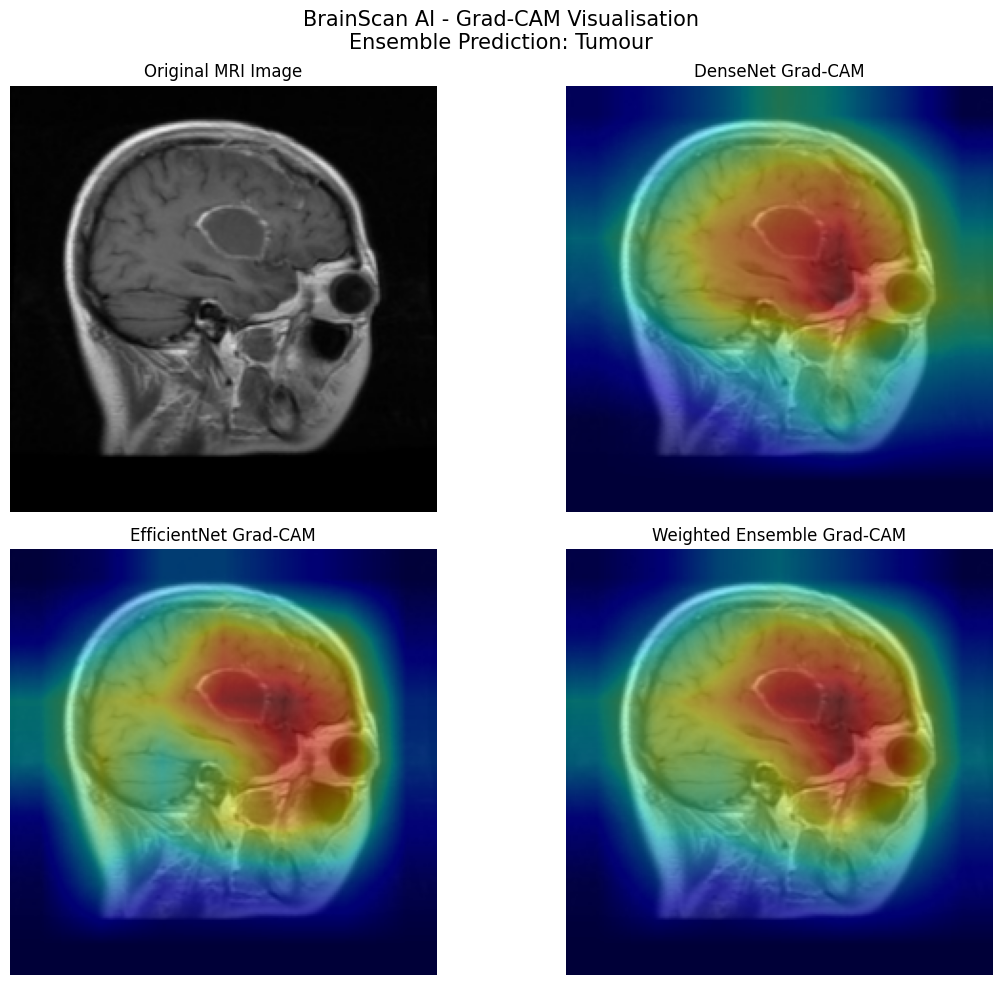

In [161]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Prepare original MRI image
original_image = image.convert("RGB").resize((224, 224))
original_array = np.array(original_image)

# Resize heatmaps
def resize_heatmap(heatmap):
    heatmap_image = Image.fromarray(
        np.uint8(255 * heatmap)
    )
    heatmap_image = heatmap_image.resize(
        (224, 224), Image.Resampling.BILINEAR
    )
    return np.array(heatmap_image) / 255.0


dense_resized = resize_heatmap(dense_heatmap)
efficient_resized = resize_heatmap(efficient_heatmap)
combined_resized = resize_heatmap(combined_heatmap)


# Display MRI and heatmap overlays
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(original_array)
axes[0, 0].set_title("Original MRI Image")

axes[0, 1].imshow(original_array)
axes[0, 1].imshow(
    dense_resized, cmap="jet", alpha=0.45
)
axes[0, 1].set_title("DenseNet Grad-CAM")

axes[1, 0].imshow(original_array)
axes[1, 0].imshow(
    efficient_resized, cmap="jet", alpha=0.45
)
axes[1, 0].set_title("EfficientNet Grad-CAM")

axes[1, 1].imshow(original_array)
axes[1, 1].imshow(
    combined_resized, cmap="jet", alpha=0.45
)
axes[1, 1].set_title("Weighted Ensemble Grad-CAM")

for ax in axes.flat:
    ax.axis("off")

plt.suptitle(
    f"BrainScan AI - Grad-CAM Visualisation\n"
    f"Ensemble Prediction: {predicted_class}",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [162]:
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

# Find the MRI Image Analysis page
lines = code.splitlines()

for i, line in enumerate(lines):
    if 'MRI Image Analysis' in line:
        start = max(0, i - 5)
        end = min(len(lines), i + 100)

        print(f"MRI PAGE CODE (lines {start + 1}-{end})")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")
        break

MRI PAGE CODE (lines 409-513)
409: 
410: page = st.sidebar.radio(
411:     "Navigation",
412:     [
413:         "Dashboard",
414:         "MRI Image Analysis",
415:         "Analytics",
416:         "Model Information",
417:         "Analysis History"
418:     ]
419: )
420: 
421: # Store prediction history
422: if "history" not in st.session_state:
423:     st.session_state.history = []
424: 
425: 
426: # --------------------------------
427: # LOAD MODELS
428: # --------------------------------
429: 
430: try:
431:     densenet_model, efficientnet_model = load_models()
432: except Exception as error:
433:     st.error(f"Unable to load models: {error}")
434:     st.stop()
435: 
436: 
437: # --------------------------------
438: 
439: # --------------------------------
440: # DASHBOARD PAGE
441: # --------------------------------
442: 
443: if page == "Dashboard":
444: 
445:     st.markdown("""
446:         <div style="
447:             background: linear-gradient(120deg, #142747, #183

In [163]:
from pathlib import Path

code = Path("/content/app.py").read_text()
lines = code.splitlines()

for i, line in enumerate(lines):
    if 'page == "MRI Image Analysis"' in line:

        start = i
        end = min(len(lines), i + 180)

        print(f"MRI ANALYSIS CODE (lines {start + 1}-{end})")

        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")

        break
else:
    print("MRI Image Analysis section not found.")

MRI ANALYSIS CODE (lines 568-747)
568: elif page == "MRI Image Analysis":
569: 
570:     st.title("MRI Image Analysis")
571: 
572:     st.write(
573:         "Upload a brain MRI image to obtain an ensemble prediction."
574:     )
575: 
576:     uploaded_file = st.file_uploader(
577:         "Upload MRI Image",
578:         type=["png", "jpg", "jpeg"]
579:     )
580: 
581:     if uploaded_file is not None:
582: 
583:         image = Image.open(uploaded_file).convert("RGB")
584: 
585:         st.image(
586:             image,
587:             caption="Uploaded MRI Image",
588:             width=350
589:         )
590: 
591:         if st.button("Analyse MRI Image"):
592: 
593:             with st.spinner("Analysing MRI image..."):
594: 
595:                 predicted_class, score, probabilities, dense_scores, efficient_scores = (
596:                     predict_ensemble(
597:                         image,
598:                         densenet_model,
599:                         efficie

In [164]:
from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

for j in range(740, min(len(lines), 850)):
    print(f"{j + 1}: {lines[j]}")

741:                 "The final ensemble output is calculated using "
742:                 "40% DenseNet and 60% EfficientNet. Individual "
743:                 "model scores are outputs, not calibrated confidence."
744:             )
745: 
746:             st.warning(
747:                 "Research prototype only. Model scores are not "
748:                 "clinically validated probabilities or a diagnosis. "
749:                 "Results must be reviewed by qualified healthcare professionals."
750:             )
751: 
752:             # Downloadable PDF prediction report
753:             st.divider()
754:             st.subheader("Download Prediction Report")
755: 
756:             if result.get("image_bytes"):
757: 
758:                 pdf_bytes = create_prediction_pdf(
759:                     result,
760:                     result["image_bytes"],
761:                     result.get("image_name", "MRI image")
762:                 )
763: 
764:                 st.download_button(


In [165]:

from pathlib import Path
import shutil

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup_before_gradcam.py")

# Create backup
shutil.copy2(app_path, backup_path)

code = app_path.read_text()

marker = "# --------------------------------\n# LOAD MODELS\n# --------------------------------"

gradcam_functions = '''

# --------------------------------
# GRAD-CAM FUNCTIONS
# --------------------------------

def build_gradcam_models(densenet_model, efficientnet_model):

    # DenseNet feature extractor
    dense_base = densenet_model.get_layer("densenet121")

    dense_feature_extractor = tf.keras.Model(
        inputs=dense_base.input,
        outputs=[
            dense_base.get_layer("conv5_block16_concat").output,
            dense_base.output
        ]
    )

    dense_input = tf.keras.Input(shape=(224, 224, 3))

    dense_features, dense_base_output = dense_feature_extractor(
        dense_input, training=False
    )

    x = densenet_model.get_layer(
        "global_average_pooling2d"
    )(dense_base_output)

    x = densenet_model.get_layer("dropout")(
        x, training=False
    )

    dense_predictions = densenet_model.get_layer(
        "classification_output"
    )(x)

    dense_grad_model = tf.keras.Model(
        dense_input,
        [dense_features, dense_predictions]
    )

    # EfficientNet feature extractor
    efficient_base = efficientnet_model.get_layer("efficientnetb0")

    efficient_feature_extractor = tf.keras.Model(
        inputs=efficient_base.input,
        outputs=[
            efficient_base.get_layer("top_conv").output,
            efficient_base.output
        ]
    )

    efficient_input = tf.keras.Input(shape=(224, 224, 3))

    efficient_features, efficient_base_output = (
        efficient_feature_extractor(
            efficient_input, training=False
        )
    )

    x = efficientnet_model.get_layer("dropout")(
        efficient_base_output, training=False
    )

    efficient_predictions = efficientnet_model.get_layer(
        "dense"
    )(x)

    efficient_grad_model = tf.keras.Model(
        efficient_input,
        [efficient_features, efficient_predictions]
    )

    return dense_grad_model, efficient_grad_model


def generate_gradcam(grad_model, model_input, class_index):

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            model_input, training=False
        )

        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)

    weights = tf.reduce_mean(
        gradients, axis=(1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_outputs * weights[:, tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap[0])

    heatmap = heatmap / (
        tf.reduce_max(heatmap) +
        tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

'''

if "def build_gradcam_models(" in code:
    print("Grad-CAM functions already exist. No changes made.")

elif marker not in code:
    print("ERROR: Could not find the LOAD MODELS section. No changes made.")

else:
    code = code.replace(
        marker,
        gradcam_functions + "\n" + marker,
        1
    )

    app_path.write_text(code)

    print("SUCCESS: Grad-CAM functions added.")
    print("Backup:", backup_path)
    print("Updated:", app_path)


SUCCESS: Grad-CAM functions added.
Backup: /content/app_backup_before_gradcam.py
Updated: /content/app.py


In [166]:

from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

old_code = '''try:
    densenet_model, efficientnet_model = load_models()
except Exception as error:
    st.error(f"Unable to load models: {error}")
    st.stop()
'''

new_code = '''try:
    densenet_model, efficientnet_model = load_models()

    dense_grad_model, efficient_grad_model = (
        build_gradcam_models(
            densenet_model,
            efficientnet_model
        )
    )

except Exception as error:
    st.error(f"Unable to load models: {error}")
    st.stop()
'''

if old_code not in code:
    print("ERROR: Original model-loading section not found.")
else:
    code = code.replace(old_code, new_code, 1)
    app_path.write_text(code)
    print("SUCCESS: Grad-CAM models connected to loaded models.")


SUCCESS: Grad-CAM models connected to loaded models.


In [167]:
import ast

code = Path("/content/app.py").read_text()
ast.parse(code)

print("SUCCESS: No Python syntax errors.")

SUCCESS: No Python syntax errors.


In [168]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
code = app_path.read_text()

marker = '''            st.warning(
                "Research prototype only. Model scores are not "
'''

gradcam_display = '''            # --------------------------------
            # GRAD-CAM VISUALISATION
            # --------------------------------

            st.divider()
            st.subheader("Grad-CAM Model Visualisation")

            st.write(
                "Visual explanations showing image regions "
                "that influence the models' predictions."
            )

            try:
                # Recreate model inputs from uploaded MRI
                dense_input, efficient_input = preprocess_image(
                    Image.open(
                        BytesIO(result["image_bytes"])
                    ).convert("RGB")
                )

                # Use the final ensemble prediction class
                class_index = CLASS_NAMES.index(result["class"])

                # Generate individual heatmaps
                dense_heatmap = generate_gradcam(
                    dense_grad_model,
                    dense_input,
                    class_index
                )

                efficient_heatmap = generate_gradcam(
                    efficient_grad_model,
                    efficient_input,
                    class_index
                )

                # Weighted ensemble heatmap
                combined_heatmap = (
                    0.4 * dense_heatmap +
                    0.6 * efficient_heatmap
                )

                combined_heatmap = combined_heatmap / (
                    np.max(combined_heatmap) + 1e-8
                )

                # Resize heatmaps to original display size
                def resize_gradcam_heatmap(heatmap):
                    heatmap_image = Image.fromarray(
                        np.uint8(255 * heatmap)
                    )
                    heatmap_image = heatmap_image.resize(
                        (224, 224),
                        Image.Resampling.BILINEAR
                    )
                    return np.array(heatmap_image) / 255.0

                dense_resized = resize_gradcam_heatmap(
                    dense_heatmap
                )

                efficient_resized = resize_gradcam_heatmap(
                    efficient_heatmap
                )

                combined_resized = resize_gradcam_heatmap(
                    combined_heatmap
                )

                original_mri = Image.open(
                    BytesIO(result["image_bytes"])
                ).convert("RGB").resize((224, 224))

                original_array = np.array(original_mri)

                # Display four visualisations
                fig, axes = plt.subplots(
                    2, 2, figsize=(12, 10)
                )

                axes[0, 0].imshow(original_array)
                axes[0, 0].set_title("Original MRI Image")

                axes[0, 1].imshow(original_array)
                axes[0, 1].imshow(
                    dense_resized,
                    cmap="jet",
                    alpha=0.45
                )
                axes[0, 1].set_title("DenseNet Grad-CAM")

                axes[1, 0].imshow(original_array)
                axes[1, 0].imshow(
                    efficient_resized,
                    cmap="jet",
                    alpha=0.45
                )
                axes[1, 0].set_title("EfficientNet Grad-CAM")

                axes[1, 1].imshow(original_array)
                axes[1, 1].imshow(
                    combined_resized,
                    cmap="jet",
                    alpha=0.45
                )
                axes[1, 1].set_title(
                    "Weighted Ensemble Grad-CAM"
                )

                for ax in axes.flat:
                    ax.axis("off")

                fig.suptitle(
                    f"Grad-CAM Visualisation - {result['class']}",
                    fontsize=15
                )

                plt.tight_layout()
                st.pyplot(fig)
                plt.close(fig)

                st.caption(
                    "The combined visualisation is a weighted "
                    "40% DenseNet and 60% EfficientNet blend."
                )

            except Exception as gradcam_error:
                st.error(
                    f"Grad-CAM visualisation failed: {gradcam_error}"
                )

            st.info(
                "Grad-CAM visualisations show regions influencing "
                "the model outputs. They do not confirm the location "
                "of a tumour or stroke and are not clinical evidence."
            )

'''

if "Grad-CAM Model Visualisation" in code:
    print("Grad-CAM display section already exists.")

elif marker not in code:
    print("ERROR: Could not find the medical disclaimer insertion point.")

else:
    updated_code = code.replace(
        marker,
        gradcam_display + marker,
        1
    )

    try:
        ast.parse(updated_code)
        app_path.write_text(updated_code)

        print("SUCCESS: Grad-CAM visualisations added!")
        print("Original prediction section preserved.")
        print("PDF report section preserved.")
        print("Analytics section preserved.")
        print("Python syntax: VALID")

    except SyntaxError as error:
        print("Syntax error:", error)
        print("Original app.py was not changed.")


SUCCESS: Grad-CAM visualisations added!
Original prediction section preserved.
PDF report section preserved.
Analytics section preserved.
Python syntax: VALID


In [169]:
from pathlib import Path
import ast

app_path = Path("/content/app.py")
code = app_path.read_text()

# Check Python syntax
ast.parse(code)

checks = {
    "Grad-CAM model builder": "def build_gradcam_models(" in code,
    "Grad-CAM calculation": "def generate_gradcam(" in code,
    "Grad-CAM visualisation": "Grad-CAM Model Visualisation" in code,
    "Original MRI display": "Original MRI Image" in code,
    "DenseNet heatmap": "DenseNet Grad-CAM" in code,
    "EfficientNet heatmap": "EfficientNet Grad-CAM" in code,
    "Ensemble heatmap": "Weighted Ensemble Grad-CAM" in code,
    "40/60 weighting": "0.4 * dense_heatmap" in code,
    "PDF report": "create_prediction_pdf(" in code,
    "Analytics page": 'elif page == "Analytics":' in code,
    "Analysis History": 'elif page == "Analysis History":' in code,
    "Medical disclaimer": "not clinical evidence" in code
}

print("BRAINSCAN AI - FINAL VERIFICATION")
print("=" * 45)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("=" * 45)
print("Python syntax: VALID")
print("All checks passed:", all(checks.values()))

BRAINSCAN AI - FINAL VERIFICATION
PASS: Grad-CAM model builder
PASS: Grad-CAM calculation
PASS: Grad-CAM visualisation
PASS: Original MRI display
PASS: DenseNet heatmap
PASS: EfficientNet heatmap
PASS: Ensemble heatmap
PASS: 40/60 weighting
PASS: PDF report
PASS: Analytics page
PASS: Analysis History
PASS: Medical disclaimer
Python syntax: VALID
All checks passed: True


In [170]:
from pathlib import Path

code = Path("/content/app.py").read_text()

if "import matplotlib.pyplot as plt" in code:
    print("PASS: Matplotlib is imported.")
else:
    print("MISSING: Matplotlib import needs to be added.")

MISSING: Matplotlib import needs to be added.


In [171]:
from pathlib import Path
import ast

app_path = Path("/content/app.py")
code = app_path.read_text()

if "import matplotlib.pyplot as plt" in code:
    print("Matplotlib is already imported.")

else:
    # Insert alongside the existing imports
    import_marker = "import plotly.express as px"

    if import_marker in code:
        code = code.replace(
            import_marker,
            import_marker + "\nimport matplotlib.pyplot as plt",
            1
        )

        ast.parse(code)
        app_path.write_text(code)

        print("SUCCESS: Matplotlib import added.")
        print("Python syntax: VALID")

    else:
        print("ERROR: Could not find the import insertion point.")

SUCCESS: Matplotlib import added.
Python syntax: VALID


In [172]:
code = Path("/content/app.py").read_text()

print(
    "Matplotlib import:",
    "PASS" if "import matplotlib.pyplot as plt" in code else "FAIL"
)

Matplotlib import: PASS


In [173]:
!pkill -f "streamlit run"

In [174]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [175]:
import requests
import time

time.sleep(5)

response = requests.get(
    "http://localhost:8501",
    timeout=15
)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    print("SUCCESS: BrainScan AI is running!")
else:
    print("Please check the Streamlit log.")

HTTP Status: 200
SUCCESS: BrainScan AI is running!


In [176]:

from pathlib import Path
import shutil

app_path = Path("/content/app.py")
backup_path = Path("/content/app_backup_before_dark_theme.py")

# Create a backup
shutil.copy2(app_path, backup_path)

print("BACKUP CREATED:", backup_path)

# Inspect the beginning of app.py
lines = app_path.read_text().splitlines()

print("\n===== APPLICATION IMPORTS AND CONFIGURATION =====")

for i, line in enumerate(lines[:110]):
    print(f"{i + 1}: {line}")

print("\n===== EXISTING CUSTOM CSS REFERENCES =====")

for i, line in enumerate(lines):
    if "<style>" in line or "st.set_page_config" in line:
        print(f"Line {i + 1}: {line.strip()}")


BACKUP CREATED: /content/app_backup_before_dark_theme.py

===== APPLICATION IMPORTS AND CONFIGURATION =====
1: from pathlib import Path
2: from io import BytesIO
3: 
4: import streamlit as st
5: import tensorflow as tf
6: from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
7: import numpy as np
8: import pandas as pd
9: import plotly.express as px
10: import matplotlib.pyplot as plt
11: 
12: from PIL import Image
13: from datetime import datetime
14: 
15: from reportlab.lib import colors
16: from reportlab.lib.pagesizes import A4
17: from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
18: from reportlab.lib.units import mm
19: from reportlab.lib.utils import ImageReader
20: from reportlab.platypus import (
21:     SimpleDocTemplate, Paragraph, Spacer, Table,
22:     TableStyle, Image as PDFImage
23: )
24: 
25: # --------------------------------
26: 
27: 
28: # --------------------------------
29: # PDF PREDICTION REPORT GENERATOR


In [177]:

from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

print("===== PAGE CONFIGURATION AND THEME CSS =====")

for i in range(245, min(len(lines), 420)):
    print(f"{i + 1}: {lines[i]}")


===== PAGE CONFIGURATION AND THEME CSS =====
246:     document.build(story)
247: 
248:     pdf_buffer.seek(0)
249: 
250:     return pdf_buffer.getvalue()
251: 
252: 
253: 
254: # PAGE CONFIGURATION
255: # --------------------------------
256: 
257: st.set_page_config(
258:     page_title="BrainScan AI",
259:     page_icon="🧠",
260:     layout="wide"
261: )
262: 
263: CLASS_NAMES = ["Normal", "Stroke", "Tumour"]
264: 
265: # --------------------------------
266: # LOAD TRAINED MODELS
267: # --------------------------------
268: 
269: @st.cache_resource
270: def load_models():
271: 
272:     densenet = tf.keras.models.load_model(
273:         str(Path(__file__).parent / "densenet_ensemble_member.keras"),
274:         compile=False
275:     )
276: 
277:     efficientnet = tf.keras.models.load_model(
278:         str(Path(__file__).parent / "efficientnet_ensemble_member.keras"),
279:         compile=False
280:     )
281: 
282:     return densenet, efficientnet
283: 
284: 
285: # ----------

In [178]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
code = app_path.read_text()

# 1. Remove the browser-tab emoji
code = code.replace(
    '    page_icon="🧠",\n',
    ''
)

# 2. Replace the existing CSS section
start_marker = 'st.markdown("""\n<style>'
end_marker = '""", unsafe_allow_html=True)'

start = code.find(start_marker)
end = code.find(end_marker, start)

if start == -1 or end == -1:
    print("ERROR: Existing CSS section could not be located.")

else:

    end += len(end_marker)

    new_css = '''st.markdown("""
<style>

@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

:root {
    --background: #0B1220;
    --sidebar: #111C2E;
    --card: #19263A;
    --border: #2B3A50;
    --accent: #35B8A5;
    --text: #F1F5F9;
    --muted: #94A3B8;
}

/* Main application */
.stApp {
    background: var(--background);
    color: var(--text);
    font-family: 'Inter', Arial, sans-serif;
}

/* Main content area */
.main .block-container {
    padding-top: 2rem;
    padding-bottom: 3rem;
    max-width: 1450px;
}

/* Typography */
html, body, [class*="css"] {
    font-family: 'Inter', Arial, sans-serif;
}

h1, h2, h3, h4 {
    color: var(--text) !important;
    font-weight: 700 !important;
    letter-spacing: -0.4px;
}

p, label, .stMarkdown {
    color: var(--text);
}

/* Sidebar */
[data-testid="stSidebar"] {
    background: var(--sidebar);
    border-right: 1px solid var(--border);
}

[data-testid="stSidebar"] h1,
[data-testid="stSidebar"] h2,
[data-testid="stSidebar"] p {
    color: var(--text) !important;
}

/* Navigation */
[data-testid="stSidebar"] [role="radiogroup"] label {
    background: transparent;
    border-radius: 8px;
    padding: 9px;
}

[data-testid="stSidebar"] [role="radiogroup"] label:hover {
    background: var(--card);
}

/* Buttons */
.stButton button,
.stDownloadButton button {
    background: var(--accent);
    color: #071522 !important;
    border: 1px solid var(--accent);
    border-radius: 8px;
    padding: 0.65rem 1.2rem;
    font-weight: 600;
    transition: all 0.2s ease;
}

.stButton button:hover,
.stDownloadButton button:hover {
    background: #279987;
    border-color: #279987;
    color: white !important;
}

/* Cards and metrics */
[data-testid="stMetric"] {
    background: var(--card);
    border: 1px solid var(--border);
    border-radius: 12px;
    padding: 18px;
}

[data-testid="stMetricLabel"] {
    color: var(--muted) !important;
}

[data-testid="stMetricValue"] {
    color: var(--text) !important;
    font-weight: 700;
}

/* Inputs */
.stTextInput input,
.stNumberInput input,
.stTextArea textarea {
    background: var(--card) !important;
    color: var(--text) !important;
    border: 1px solid var(--border) !important;
    border-radius: 8px;
}

/* File uploader */
[data-testid="stFileUploader"] {
    background: var(--card);
    border: 1px dashed var(--accent);
    border-radius: 12px;
    padding: 12px;
}

/* Select boxes */
[data-testid="stSelectbox"] > div > div {
    background: var(--card);
    border-color: var(--border);
}

/* Tables */
[data-testid="stDataFrame"],
[data-testid="stTable"] {
    border: 1px solid var(--border);
    border-radius: 10px;
}

/* Expanders */
[data-testid="stExpander"] {
    background: var(--card);
    border: 1px solid var(--border);
    border-radius: 10px;
}

/* Dividers */
hr {
    border-color: var(--border);
}

/* Progress bars */
.stProgress > div > div > div {
    background: var(--accent);
}

/* Tabs */
button[data-baseweb="tab"] {
    color: var(--muted);
    font-weight: 600;
}

button[data-baseweb="tab"][aria-selected="true"] {
    color: var(--accent);
}

/* Captions */
.stCaption, [data-testid="stCaptionContainer"] {
    color: var(--muted) !important;
}

</style>
""", unsafe_allow_html=True)'''

    code = code[:start] + new_css + code[end:]

    # 3. Remove emoji from sidebar title
    code = code.replace(
        'st.sidebar.title("🧠 BrainScan AI")',
        'st.sidebar.title("BrainScan AI")'
    )

    # Validate before saving
    try:
        ast.parse(code)
        app_path.write_text(code)

        print("SUCCESS: Dark theme installed.")
        print("SUCCESS: Browser-tab emoji removed.")
        print("SUCCESS: Sidebar emoji removed.")
        print("SUCCESS: Inter typography configured.")
        print("Python syntax: VALID")

    except SyntaxError as error:
        print("Syntax error:", error)
        print("Original app.py was not changed.")


SUCCESS: Dark theme installed.
SUCCESS: Browser-tab emoji removed.
SUCCESS: Sidebar emoji removed.
SUCCESS: Inter typography configured.
Python syntax: VALID


In [179]:
from pathlib import Path
import ast

code = Path("/content/app.py").read_text()
ast.parse(code)

checks = {
    "Dark background": "#0B1220" in code,
    "Dark sidebar": "#111C2E" in code,
    "Teal accent": "#35B8A5" in code,
    "Inter font": "Inter" in code,
    "Browser emoji removed": 'page_icon="🧠"' not in code,
    "Sidebar emoji removed": 'st.sidebar.title("🧠' not in code
}

for name, passed in checks.items():
    print(("PASS" if passed else "FAIL") + ": " + name)

print("Python syntax: VALID")

PASS: Dark background
PASS: Dark sidebar
PASS: Teal accent
PASS: Inter font
PASS: Browser emoji removed
PASS: Sidebar emoji removed
Python syntax: VALID


In [180]:

from pathlib import Path
import re

code = Path("/content/app.py").read_text().splitlines()

print("===== DASHBOARD TEXT AND SYMBOLS =====")

for line_number, line in enumerate(code, start=1):
    if any(word in line.lower() for word in [
        "st.title",
        "st.header",
        "st.subheader",
        "st.sidebar.title",
        "st.button",
        "st.download_button",
        "st.metric",
        "st.success",
        "st.warning",
        "st.info",
        "st.error",
        "st.radio"
    ]):
        print(f"{line_number}: {line.strip()}")


===== DASHBOARD TEXT AND SYMBOLS =====
551: st.sidebar.title("BrainScan AI")
692: st.error(f"Unable to load models: {error}")
721: st.subheader("System Overview")
739: st.metric(
746: st.metric(
753: st.metric(
760: st.subheader("How BrainScan AI Works")
786: st.subheader("Available Classification Categories")
804: st.subheader("Get Started")
812: st.success(
817: st.warning(
829: st.title("MRI Image Analysis")
850: if st.button("Analyse MRI Image"):
901: st.subheader("Final Ensemble Prediction")
903: st.success(
907: st.metric(
912: st.subheader("Individual Class Scores")
924: st.metric(
938: st.subheader("Ensemble Score Comparison")
973: st.subheader("Individual CNN Model Contributions")
1010: st.subheader("Grad-CAM Model Visualisation")
1132: st.error(
1136: st.info(
1142: st.warning(
1150: st.subheader("Download Prediction Report")
1160: st.download_button(
1173: st.info(
1187: st.title("📊 MRI Prediction Analytics")
1219: st.subheader("Prediction Summary")
1249: st.subheader("Predi

In [181]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
code = app_path.read_text()

replacements = {
    'st.title("📊 MRI Prediction Analytics")':
        'st.title("MRI Prediction Analytics")',

    'st.title("🧠 Model Information")':
        'st.title("Model Information")',

    'st.title("📋 MRI Analysis History")':
        'st.title("MRI Analysis History")'
}

for old, new in replacements.items():
    if old in code:
        code = code.replace(old, new)
        print("UPDATED:", old)
    else:
        print("NOT FOUND:", old)

# Validate before saving
try:
    ast.parse(code)
    app_path.write_text(code)
    print("\nSUCCESS: Remaining page-title emojis removed.")
    print("Python syntax: VALID")

except SyntaxError as error:
    print("ERROR:", error)


UPDATED: st.title("📊 MRI Prediction Analytics")
UPDATED: st.title("🧠 Model Information")
UPDATED: st.title("📋 MRI Analysis History")

SUCCESS: Remaining page-title emojis removed.
Python syntax: VALID


In [182]:
from pathlib import Path

code = Path("/content/app.py").read_text()

print("Analytics emoji removed:", "📊" not in code)
print("Model emoji removed:", "🧠" not in code)
print("History emoji removed:", "📋" not in code)

Analytics emoji removed: False
Model emoji removed: False
History emoji removed: True


In [183]:

from pathlib import Path

code = Path("/content/app.py").read_text().splitlines()

for number, line in enumerate(code, start=1):
    if "📊" in line or "🧠" in line:
        print(f"Line {number}: {line.strip()}")


Line 712: 🧠 Welcome to BrainScan AI
Line 771: st.markdown("### 🧠 Analyse")
Line 778: st.markdown("### 📊 Results")


In [184]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
code = app_path.read_text()

replacements = {
    "🧠 Welcome to BrainScan AI": "Welcome to BrainScan AI",
    'st.markdown("### 🧠 Analyse")':
        'st.markdown("### Analyse")',
    'st.markdown("### 📊 Results")':
        'st.markdown("### Results")'
}

for old, new in replacements.items():
    if old in code:
        code = code.replace(old, new)
        print("UPDATED:", old)
    else:
        print("NOT FOUND:", old)

ast.parse(code)
app_path.write_text(code)

print("\nSUCCESS: Remaining decorative emojis removed.")
print("Python syntax: VALID")


UPDATED: 🧠 Welcome to BrainScan AI
UPDATED: st.markdown("### 🧠 Analyse")
UPDATED: st.markdown("### 📊 Results")

SUCCESS: Remaining decorative emojis removed.
Python syntax: VALID


In [185]:
from pathlib import Path

code = Path("/content/app.py").read_text()

print("Brain emoji removed:", "🧠" not in code)
print("Chart emoji removed:", "📊" not in code)
print("History emoji removed:", "📋" not in code)

Brain emoji removed: True
Chart emoji removed: True
History emoji removed: True


In [186]:

from pathlib import Path

lines = Path("/content/app.py").read_text().splitlines()

print("===== DASHBOARD PAGE =====")

for i in range(700, min(len(lines), 830)):
    print(f"{i + 1}: {lines[i]}")


===== DASHBOARD PAGE =====
701: 
702: if page == "Dashboard":
703: 
704:     st.markdown("""
705:         <div style="
706:             background: linear-gradient(120deg, #142747, #183E70);
707:             padding: 35px;
708:             border-radius: 16px;
709:             margin-bottom: 25px;
710:         ">
711:             <h1 style="color:white; margin-bottom:8px;">
712:                 Welcome to BrainScan AI
713:             </h1>
714:             <p style="color:#D6E7FF; font-size:17px;">
715:                 AI-assisted brain MRI classification using
716:                 DenseNet and EfficientNet.
717:             </p>
718:         </div>
719:     """, unsafe_allow_html=True)
720: 
721:     st.subheader("System Overview")
722: 
723:     st.write("""
724:     BrainScan AI is a research prototype designed to analyse
725:     uploaded brain MRI images and classify them into three
726:     categories: Tumour, Stroke and Normal.
727: 
728:     The system combines predictions fro

In [187]:

from pathlib import Path
import ast

app_path = Path("/content/app.py")
code = app_path.read_text()

start_marker = 'if page == "Dashboard":'
end_marker = '# MRI IMAGE ANALYSIS PAGE'

start = code.find(start_marker)
end = code.find(end_marker, start)

if start == -1 or end == -1:
    print("ERROR: Dashboard section could not be located.")

else:
    new_dashboard = '''if page == "Dashboard":

    st.markdown("""
        <div style="
            background: linear-gradient(120deg, #14243A, #174B5A);
            padding: 38px;
            border: 1px solid #28566A;
            border-radius: 16px;
            margin-bottom: 28px;
        ">
            <p style="
                color: #55CBBB;
                font-size: 12px;
                font-weight: 700;
                letter-spacing: 2px;
                margin-bottom: 10px;
            ">BRAIN MRI CLASSIFICATION SYSTEM</p>
            <h1 style="
                color: #F1F5F9;
                font-size: 34px;
                margin: 0 0 12px 0;
            ">Welcome to BrainScan AI</h1>
            <p style="
                color: #CBD5E1;
                font-size: 16px;
                margin: 0;
            ">
                AI-assisted brain MRI classification powered by
                DenseNet and EfficientNet.
            </p>
        </div>
    """, unsafe_allow_html=True)

    st.subheader("System Overview")

    st.write(
        "BrainScan AI is a research prototype designed to analyse "
        "uploaded brain MRI images and classify them into three "
        "categories: Tumour, Stroke and Normal. It combines the "
        "outputs of two trained convolutional neural network models "
        "to generate a final classification result."
    )

    total_analysed = len(st.session_state.history)

    col1, col2, col3 = st.columns(3)

    with col1:
        st.metric(
            "CNN Models",
            "2",
            help="DenseNet and EfficientNet"
        )

    with col2:
        st.metric(
            "Classification Categories",
            "3",
            help="Tumour, Stroke and Normal"
        )

    with col3:
        st.metric(
            "Images Analysed This Session",
            total_analysed
        )

    st.divider()

    st.subheader("How BrainScan AI Works")

    step1, step2, step3 = st.columns(3)

    workflow_cards = [
        (
            "01",
            "Upload MRI Image",
            "Upload a brain MRI image in JPG, JPEG or PNG format."
        ),
        (
            "02",
            "AI Analysis",
            "DenseNet and EfficientNet process the image and "
            "generate their classification scores."
        ),
        (
            "03",
            "View Results",
            "The system combines both model outputs and displays "
            "the final predicted category."
        )
    ]

    for column, card in zip(
        [step1, step2, step3],
        workflow_cards
    ):
        with column:
            st.markdown(f"""
                <div style="
                    background: #19263A;
                    border: 1px solid #2B3A50;
                    border-radius: 12px;
                    padding: 22px;
                    min-height: 155px;
                ">
                    <div style="
                        color: #35B8A5;
                        font-size: 13px;
                        font-weight: 700;
                        margin-bottom: 14px;
                    ">STEP {card[0]}</div>
                    <div style="
                        color: #F1F5F9;
                        font-size: 17px;
                        font-weight: 700;
                        margin-bottom: 10px;
                    ">{card[1]}</div>
                    <div style="
                        color: #94A3B8;
                        font-size: 13px;
                        line-height: 1.6;
                    ">{card[2]}</div>
                </div>
            """, unsafe_allow_html=True)

    st.divider()

    st.subheader("Classification Categories")

    tumour, stroke, normal = st.columns(3)

    categories = [
        (tumour, "Tumour", "Classification category for brain MRI images showing tumour patterns."),
        (stroke, "Stroke", "Classification category for brain MRI images showing stroke patterns."),
        (normal, "Normal", "Classification category for images classified as normal.")
    ]

    for column, name, description in categories:
        with column:
            st.markdown(f"""
                <div style="
                    background: #19263A;
                    border: 1px solid #2B3A50;
                    border-top: 3px solid #35B8A5;
                    border-radius: 10px;
                    padding: 20px;
                    min-height: 125px;
                ">
                    <div style="
                        color: #F1F5F9;
                        font-size: 18px;
                        font-weight: 700;
                        margin-bottom: 10px;
                    ">{name}</div>
                    <div style="
                        color: #94A3B8;
                        font-size: 13px;
                        line-height: 1.6;
                    ">{description}</div>
                </div>
            """, unsafe_allow_html=True)

    st.divider()

    st.subheader("Get Started")

    st.write(
        "Open MRI Image Analysis from the sidebar to upload an "
        "image and generate a prediction."
    )

    if total_analysed > 0:
        st.success(
            f"You have analysed {total_analysed} image(s) "
            "during this dashboard session."
        )

    st.warning(
        "Research prototype only. This system is not clinically "
        "validated and must not be used as a replacement for "
        "professional medical diagnosis."
    )


'''

    updated_code = code[:start] + new_dashboard + code[end:]

    try:
        ast.parse(updated_code)
        app_path.write_text(updated_code)

        print("SUCCESS: Dashboard layout upgraded.")
        print("SUCCESS: Welcome banner redesigned.")
        print("SUCCESS: Workflow cards added.")
        print("SUCCESS: Classification cards added.")
        print("SUCCESS: Session metrics preserved.")
        print("SUCCESS: Medical disclaimer preserved.")
        print("Python syntax: VALID")

    except SyntaxError as error:
        print("ERROR: Syntax validation failed:", error)
        print("The existing app.py was not changed.")


SUCCESS: Dashboard layout upgraded.
SUCCESS: Welcome banner redesigned.
SUCCESS: Workflow cards added.
SUCCESS: Classification cards added.
SUCCESS: Session metrics preserved.
SUCCESS: Medical disclaimer preserved.
Python syntax: VALID


In [188]:
from pathlib import Path
import ast

code = Path("/content/app.py").read_text()
ast.parse(code)

checks = {
    "Dashboard page exists": 'if page == "Dashboard":' in code,
    "Welcome banner exists": "Welcome to BrainScan AI" in code,
    "Workflow cards exist": "Upload MRI Image" in code,
    "Classification categories exist": "Classification Categories" in code,
    "Session metrics preserved": "Images Analysed This Session" in code,
    "Medical disclaimer preserved": "not clinically" in code,
    "MRI page preserved": 'elif page == "MRI Image Analysis":' in code
}

for name, passed in checks.items():
    print(("PASS" if passed else "FAIL") + ": " + name)

print("Python syntax: VALID")

PASS: Dashboard page exists
PASS: Welcome banner exists
PASS: Workflow cards exist
PASS: Classification categories exist
PASS: Session metrics preserved
PASS: Medical disclaimer preserved
PASS: MRI page preserved
Python syntax: VALID


In [189]:
!pkill -f "streamlit run"

In [190]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [191]:
import requests
import time

time.sleep(5)

response = requests.get("http://localhost:8501", timeout=15)

print("Application status:", response.status_code)

Application status: 200
